# Forecasting boiling in descriptor space

**Task.** Predict the future of a boiling simulation — not pixel by pixel, but in the same
13-dimensional descriptor space the companion decoder notebook renders frames from:
per-region void fractions, mean temperatures and hot-wall fractions, the Sauter diameter,
the bubble count, plus the wall temperature as a case scalar. Given a 32-step window (3.2 s)
of descriptors, each model predicts the *residual over persistence* for the next step;
evaluation then rolls the models autoregressively — feeding them their own predictions — for
up to 80 steps, and up to 400 on held-out conditions.

**Why a ladder.** Four model classes share one rollout, one sampler and one metric, so their
differences are attributable to the class rather than the plumbing: **F0 persistence** (the
null model — repeat the last state; every competitor must beat it, and it is the natural
default for design questions); **F1 mechanism hybrid** (wall-superheat accumulation drives a
quiet→burst switch with regime-wise autoregressions — closed form, fit in seconds, the only
model with the physics written in); **F2 TCN** (dilated causal convolutions, 37 k
parameters, receptive field of 125 steps — longer than the input window); **F3 ESN** (a
400-unit random reservoir with a ridge readout — closed form).

**Headline of this run.** Short-range forecasting works, and it is physics: the mechanism
model beats persistence one step ahead (2.9 % vs 3.9 %), and the TCN wins at horizon 20
(34.8 % vs 40.2 %). Long-range *point* forecasting of the void variables does not: at
horizon 80 the best model is persistence (41.9 %), and a chaos-floor experiment — following
the nearest real trajectory from another condition — already diverges by 45.5 %. The thermal
variables stay predictable to 0.3–1 % over the same horizon. Section 4 gives the physical
argument.

**Scope.** The forecaster half of the surrogate pipeline: forecast trajectories are exported
as decoder asks, so predicted descriptors can be rendered as frames. Same 15 files, same
file-level splits, same descriptor extractor as the decoder notebook — identical by design.

## 1 · Configuration, discovery, streaming extraction, splits, normalization

One `.h5` file is one experiment; no window and no rollout ever crosses a file boundary. The
cell discovers the files by glob (drop or remove `.h5` files in `DATA_DIR` — the code does
not change), resolves each file's wall temperature from metadata or the file name, and fixes
the hot threshold *before* extraction so that one streaming pass suffices. Frames are read in
64-frame chunks and reduced on the fly: the raw corpus is never resident — memory is the
30 015 × 17 descriptor table. Splits are **whole files** (8 train / 4 val / 3 test,
stratified by boiling regime and dealt across the temperature order so each split spans the
condition range): every validation and test condition is unseen, and no timeline is shared
between splits — with file-level splits there is no within-file boundary left to leak
across. The split map figure makes the stratification visible. Normalization statistics are
computed from training files only. The extractor is the decoder notebook's descriptor code
plus one extra column — the bubble count, from the same connected-component labelling as
D32 — because nucleation onset is defined on it. After this cell the frames are never read
again: everything downstream, including the decoder hand-off, runs on the descriptor table.

[data] 15 file(s) discovered under G:\BoilDesc
  Twall_100                dfun 2001x512x512  keys=(dfun,temperature)  wallTemp=100 (filename)  t_hot=95
  Twall_107                dfun 2001x512x512  keys=(dfun,temperature)  wallTemp=107 (filename)  t_hot=102
  Twall_75                 dfun 2001x512x512  keys=(dfun,temperature)  wallTemp=75 (filename)  t_hot=70
  Twall_98                 dfun 2001x512x512  keys=(dfun,temperature)  wallTemp=98 (filename)  t_hot=93
  Twall_10                 dfun 2001x288x192  keys=(dfun,temperature)  wallTemp=10 (filename)  t_hot=5
  Twall_13                 dfun 2001x288x192  keys=(dfun,temperature)  wallTemp=13 (filename)  t_hot=8
  Twall_14                 dfun 2001x288x192  keys=(dfun,temperature)  wallTemp=14 (filename)  t_hot=9
  Twall_15                 dfun 2001x288x192  keys=(dfun,temperature)  wallTemp=15 (filename)  t_hot=10
  Twall_17                 dfun 2001x288x192  keys=(dfun,temperature)  wallTemp=17 (filename)  t_hot=12
  Twall_18       

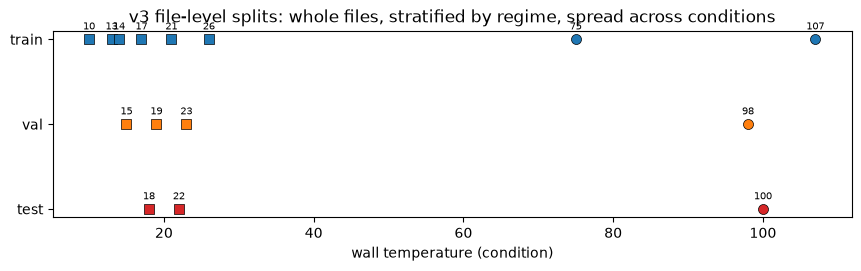

[fig] split map -> FC_splitmap.png
[crop] frame shapes differ -> centre-cropping everything to 288x192
  [extract] Twall_100                2001 frames  wallTemp=100  dt=0.1s  (3s elapsed)
  [extract] Twall_107                2001 frames  wallTemp=107  dt=0.1s  (6s elapsed)
  [extract] Twall_75                 2001 frames  wallTemp=75  dt=0.1s  (8s elapsed)
  [extract] Twall_98                 2001 frames  wallTemp=98  dt=0.1s  (11s elapsed)
  [extract] Twall_10                 2001 frames  wallTemp=10  dt=0.1s  (13s elapsed)
  [extract] Twall_13                 2001 frames  wallTemp=13  dt=0.1s  (14s elapsed)
  [extract] Twall_14                 2001 frames  wallTemp=14  dt=0.1s  (15s elapsed)
  [extract] Twall_15                 2001 frames  wallTemp=15  dt=0.1s  (17s elapsed)
  [extract] Twall_17                 2001 frames  wallTemp=17  dt=0.1s  (18s elapsed)
  [extract] Twall_18                 2001 frames  wallTemp=18  dt=0.1s  (20s elapsed)
  [extract] Twall_19                 2

In [1]:
# ============================================================================
# CELL 1 · configuration, file discovery, streaming extraction, splits, norm
# ----------------------------------------------------------------------------
# Decisions worth knowing about:
#  * every tunable is a key of CFG - the code body contains no magic numbers;
#  * files are discovered by glob (add/remove .h5 files in DATA_DIR, not code);
#    ONE FILE = ONE EXPERIMENT: windows are built from FILE_ROWS[stem] only, so
#    no window (and no rollout) can ever straddle two experiments;
#  * the per-file hot threshold is resolved BEFORE extraction (wallTemp from
#    attrs or filename; T-statistics fallback only when wallTemp is missing),
#    so one streaming pass extracts everything with the correct threshold;
#  * extraction is STREAMED per file in chunks: frames are never all resident -
#    RAM is the (N x L) indicator table, not the raw corpus;
#  * ONE extractor (extract_theta) defines the indicator vector; nbub is added
#    (same connected-component labeling as D32) because it is the column the
#    nucleation/onset tests are built on;
#  * v3 splits are WHOLE FILES: every .h5 file is assigned entirely to train,
#    val or test (~half / quarter / quarter of the file count, flexible in N),
#    STRATIFIED by boiling regime (boiling vs single-bubble, from wallTemp) so
#    a split never silently loses a whole physics regime, and dealt across the
#    wallTemp-sorted order so each split spans the condition range;
#  * consequence: every val/test condition is NEVER trained on (cross-condition
#    by construction) and no timeline is shared between splits - there is no
#    within-file boundary to leak across;
#  * normalization statistics are computed on the TRAIN files only (no leakage).
# ============================================================================
import os, re, glob, math, time, warnings
import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
from scipy import ndimage

warnings.filterwarnings('ignore')
pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 60)

CFG = dict(
    # ---------------- data discovery / loading ----------------
    DATA_DIR        = r'G:\BoilDesc',      # folder that holds the .h5 files (searched recursively)
    OUT_SUBDIR      = 'src',               # artifacts go to DATA_DIR/OUT_SUBDIR if it exists
    KEY_DFUN        = 'dfun',              # exact dataset name first, fuzzy 3-D match as fallback
    KEY_T           = 'temperature',
    WTEMP_ATTRS     = ('wall_temperature', 'wallTemp', 'wall_temp'),
    WTEMP_FN_REGEX  = r'twall[_-]?(\d+(?:\.\d+)?)',   # fallback: parse the file name
    DT_ATTRS        = ('dt', 'time_step', 'deltaT'),
    DT_DEFAULT      = 0.1,                 # s, used only if the file says nothing
    FRAME_STRIDE    = 1,                   # forecasting needs CONTIGUOUS frames - keep 1
    FRAME_LIMIT     = None,                # int: cap frames per file (debug runs)
    ALLOW_CROP      = True,                # centre-crop if files differ in shape
    CASE_OVERRIDE   = {},                  # {'Twall_95': {'wallTemp': 95.0}, ...} manual pinning
    EXTRA_INCLUDE   = [],                  # force these case scalars into the conditioning
    EXTRA_EXCLUDE   = [],
    MAX_EXTRA       = 8,
    CHUNK           = 64,                  # frames read per h5 slice (streaming)
    # ---------------- descriptor / segmentation (M4 conventions) ----------------
    N_REGIONS       = 5,
    REGION_AXIS     = 'y',
    REGION_FLIP     = False,
    TAU_DFUN        = 0.0,                 # gas where dfun > TAU
    T_HOT_MODE      = 'wall_minus_margin', # or 'absolute'
    T_HOT_MARGIN    = 5.0,                 # degC below wall temperature counts as hot
    T_HOT_ABS       = 65.0,
    T_MEAN_LIQUID   = False,
    MIN_BUB_PIX     = 6,                   # smaller connected components are noise
    LIVE_STD_TH     = 1e-6,                # column is "live" if its std exceeds this
    # ---------------- splits (v3: whole files) ----------------
    SPLIT_LEVEL     = 'file',              # v3: ONE split label per WHOLE file
    TRAIN_FRAC      = 0.50,                # target fraction of FILES per split
    VAL_FRAC        = 0.25,                # (counts adapt to the number of files;
    TEST_FRAC       = 0.25,                #  every split keeps at least one file)
    BOILING_TWALL_MIN = 70.0,              # wallTemp >= this -> 'boiling' category,
                                           # else 'single_bubble'; splits are
                                           # STRATIFIED by this regime
    CATEGORY_OVERRIDE = {},                # {'Twall_75': 'boiling', ...} manual pinning
    EVAL_START_TARGET = 336,               # v3: aimed TOTAL test rollout starts;
                                           # EVAL_MAX_STARTS adapts per test file
    DENSE_CAL_CAP   = 192,                 # cap on VAL dense quiescent windows
    DENSE_SCAN_CAP  = 240,                 # cap on TEST dense quiescent windows
    SEED            = 0,
    # ---------------- forecasting task ----------------
    WIN             = 32,                  # past-window length (steps). v2: 12 -> 32 so the
                                           # window covers ~half a quiet (superheat-ramp) phase;
                                           # the TCN receptive field and the ESN memory extend
                                           # further back than the raw window (see CELL 2).
    HORIZONS        = [1, 2, 5, 10, 20, 40, 80],
    H_MAX           = 80,                  # rollout length for evaluation
    H_MID           = 20,                  # quick-eval horizon during training
    EVAL_STRIDE     = 5,                   # spacing of rollout start points
    EVAL_MAX_STARTS = 24,                  # cap per file x region
    XVAL_HMAX       = 400,                 # long-range rollout on the held-out file
    EVENT_TOL       = 8,                   # steps: appearance-event match tolerance
    ONSET_TH        = 0.5,                 # fallback threshold (decoded nbub >= th -> present)
    QUIET_TAIL      = 16,                  # v2: a window counts as QUIESCENT when its last
                                           # QUIET_TAIL frames are bubble-free (burst cycles
                                           # leave ~26-30 quiet steps; requiring all WIN=32
                                           # frames quiet would empty the onset analysis).
    ONSET_TH_GRID   = (0.1, 0.2, 0.3, 0.5, 0.75, 1.0, 1.5, 2.0),   # v2: per-model threshold
                                           # CALIBRATED on validation (see CELL 5) - fixes the
                                           # v1 operating point (fixed 0.5 for all models).
    BLOWUP_K        = 5.0,                 # rollout FE > K x median -> blow-up start
    CLAMP_ROLLOUT   = True,                # physical guard during rollout (counted, reported)
    # ---------------- F1 mech-hybrid (closed form) ----------------
    MBH_LAGS        = 2,                   # AR lags per regime
    MBH_LAMBDA      = 1e-2,                # ridge for the regime ARs + onset-time regressor
    MBH_TAU_SOFT    = 2.0,                 # steps: softmax width of the quiet->burst switch
    MBH_TAU_CAP     = 150,                 # steps: cap on the onset-time regressand
    MBH_SLOPE_DT    = 8,                   # steps used for the superheat-slope feature
    # ---------------- F2 TCN (gradient trained, rollout-trained) ----------------
    TCN_CH          = 48,                  # channels per dilated block
    TCN_BLOCKS      = 5,                   # dilations 1,2,4,8,16 -> receptive field 63 > WIN
    TCN_KERNEL      = 3,
    DROPOUT         = 0.1,
    PUSH_WARM       = 10,                  # epochs of pure 1-step (teacher-forced) training
    PUSH_KMAX       = 8,                   # v2: PUSHFORWARD training - after warm-up, unroll K
                                           # steps feeding the model its OWN predictions back,
                                           # K ramping 1->KMAX. Trains the rollout directly
                                           # (the v1 decoupling: 1-step loss down, rollout flat).
    # ---------------- F3 ESN (closed form) ----------------
    ESN_SIZE        = 400,                 # reservoir units
    ESN_RADIUS      = 0.95,                # spectral radius (< 1 -> contractive rollout)
    ESN_LEAK        = 0.3,                 # leak rate (reservoir memory timescale)
    ESN_ISCALE      = 0.5,                 # input scaling
    ESN_LAMBDA      = 1e-2,                # ridge for the readout
    # ---------------- training (TCN) ----------------
    LOSS_W          = dict(alpha=1.0, Tmean=1.0, f_hot=1.0, D32=2.0, nbub=6.0),
    EPOCHS          = 80, BATCH = 64, LR = 1.5e-3, WEIGHT_DECAY = 1e-5,
    GRAD_CLIP       = 1.0, WARMUP_EPOCHS = 3, PATIENCE = 12, EVAL_EVERY = 2,
    QUICK_VAL_STARTS = 48,                 # global cap on quick-validation rollouts (speed)
    # ---------------- reporting ----------------
    DPI             = 150,
)
SEED = CFG['SEED']
np.random.seed(SEED)

# ------------------------- file discovery ------------------------------------
def find_files(root):
    bad = ('.venv', 'site-packages', '__pycache__', '.git')
    out = []
    for pat in ('*.h5', '*.hdf5'):
        out += glob.glob(os.path.join(root, '**', pat), recursive=True)
    return sorted({os.path.normpath(p) for p in out if not any(b in p for b in bad)})

FILES = find_files(CFG['DATA_DIR'])
assert FILES, f"no .h5 files under {CFG['DATA_DIR']} - set CFG['DATA_DIR']"
print(f"[data] {len(FILES)} file(s) discovered under {CFG['DATA_DIR']}")

# artifacts land in DATA_DIR/OUT_SUBDIR when that folder exists
_out = os.path.join(CFG['DATA_DIR'], CFG['OUT_SUBDIR'])
OUT_DIR = _out if os.path.isdir(_out) else CFG['DATA_DIR']
os.makedirs(OUT_DIR, exist_ok=True)
PREFIX = 'FC'

# ------------------------- schema helpers (M4 conventions) -------------------
def as_float(v):
    try:
        a = np.asarray(v)
        if a.dtype.kind in 'US':  return None
        a = np.ravel(a)
        return float(a[0]) if a.size == 1 else None
    except Exception:
        return None

def scalar_candidates(f):
    out = {}
    for k, v in f.attrs.items():
        x = as_float(v)
        if x is not None:
            out[k] = x
    for k in f.keys():
        try:
            d = f[k]
            if isinstance(d, h5py.Dataset) and d.ndim <= 1 and d.size <= 1:
                x = as_float(d[()])
                if x is not None and k not in out:
                    out[k] = x
        except Exception:
            pass
    return out

def find_dfun_key(f):
    k = CFG['KEY_DFUN']
    if k in f.keys() and f[k].ndim == 3:
        return k
    for k in f.keys():
        if isinstance(f[k], h5py.Dataset) and f[k].ndim == 3 and 'dfun' in k.lower():
            return k
    return None

def find_T_key(f):
    cand = [k for k in f.keys()
            if isinstance(f[k], h5py.Dataset) and f[k].ndim == 3 and 'temp' in k.lower()]
    cand.sort(key=lambda k: (k.lower() != 'temperature',
                             any(w in k.lower() for w in ('wall', 'sat', 'subcool'))))
    return cand[0] if cand else None

def walltemp_of(path, sc):
    for name in CFG['WTEMP_ATTRS']:
        for k in sc:
            if k.lower() == name.lower():
                return sc[k], k
    for k, v in sc.items():
        if 'wall' in k.lower() and 'temp' in k.lower():
            return v, k
    m = re.search(CFG['WTEMP_FN_REGEX'], os.path.basename(path), re.I)
    if m:
        return float(m.group(1)), 'filename'
    return float('nan'), None

# ------------------------- pass 1: inventory (shapes, scalars, t_hot) --------
INFO = {}
for p in FILES:
    stem = os.path.splitext(os.path.basename(p))[0]
    with h5py.File(p, 'r') as f:
        kd, kt = find_dfun_key(f), find_T_key(f)
        if kd is None or kt is None:
            raise RuntimeError(f"{p}: could not locate 3-D dfun/temperature datasets "
                               f"(keys={list(f.keys())}). Adjust CFG['KEY_DFUN']/CFG['KEY_T'].")
        sc = scalar_candidates(f)
        nt, h, w = f[kd].shape
    wt, wt_src = walltemp_of(p, sc)
    # hot threshold resolved BEFORE extraction (T-stats fallback only if no wallTemp)
    if CFG['T_HOT_MODE'] == 'absolute':
        th_ = float(CFG['T_HOT_ABS'])
    elif np.isfinite(wt):
        th_ = float(wt - CFG['T_HOT_MARGIN'])
    else:
        with h5py.File(p, 'r') as f:
            Ts = np.asarray(f[kt][:: max(nt // 50, 1)], dtype=np.float64)
        th_ = float(Ts.mean() + Ts.std())
    INFO[stem] = dict(path=p, kd=kd, kt=kt, nt=nt, h=h, w=w, sc=sc,
                      wallTemp=wt, wt_src=wt_src, t_hot=th_)
    print(f"  {stem:24s} dfun {nt}x{h}x{w}  keys=({kd},{kt})"
          f"  wallTemp={wt:g} ({wt_src})  t_hot={th_:g}")

# ------------------------- v3: file-level split assignment ---------------------
# Whole files -> train/val/test. Counts follow TRAIN/VAL/TEST_FRAC of the file
# count (flexible: any N >= 3 works and every split keeps at least one file),
# and the assignment is STRATIFIED by boiling regime (from wallTemp) so a split
# never silently loses a whole physics regime. Within a category, files are
# dealt across the wallTemp-sorted order to the split with the largest
# remaining need (ties -> least recently served), so every split spans the
# condition range instead of clustering at one end.
def split_counts(m):
    """(train, val, test) file counts for one category holding m files."""
    if m <= 0:
        return (0, 0, 0)
    if m == 1:
        return (1, 0, 0)                    # too few to hold out - train on it
    if m == 2:
        return (1, 1, 0)
    c_tr = max(1, int(round(CFG['TRAIN_FRAC'] * m)))
    c_va = max(1, int(round(CFG['VAL_FRAC'] * m)))
    c_tr = min(c_tr, m - 2)                 # leave room for >= 1 val, >= 1 test
    c_va = min(c_va, m - c_tr - 1)
    return (c_tr, c_va, m - c_tr - c_va)

def deal_files(stems_sorted, counts):
    """deal wallTemp-sorted files to splits: largest remaining need first, ties
    to the least recently served split -> each split spans the range."""
    need = dict(zip(('train', 'val', 'test'), counts))
    last = {k: -1 for k in need}
    out = {}
    for i, s in enumerate(stems_sorted):
        cand = [k for k in ('train', 'val', 'test') if need[k] > 0]
        k = sorted(cand, key=lambda q: (-need[q], last[q]))[0]
        out[s] = k
        need[k] -= 1
        last[k] = i
    return out

def category_of(stem):
    if stem in CFG['CATEGORY_OVERRIDE']:
        return str(CFG['CATEGORY_OVERRIDE'][stem])
    wt = float(INFO[stem]['wallTemp'])
    if not np.isfinite(wt):
        return 'unclassified'
    return 'boiling' if wt >= CFG['BOILING_TWALL_MIN'] else 'single_bubble'

def repair_empty_splits(assign, wt_of):
    """global guarantee: with >= 3 files every split holds at least one file.
    Moves the median-wallTemp file of the largest split into any empty role."""
    for role in ('val', 'test'):
        while not [s for s in assign if assign[s] == role]:
            pool = max(('train', 'val', 'test'),
                       key=lambda r: sum(v == r for v in assign.values()))
            cand = [s for s in assign if assign[s] == pool]
            wts = sorted(wt_of(s) for s in assign if np.isfinite(wt_of(s)))
            med = wts[len(wts) // 2] if wts else np.inf
            mv = min(cand, key=lambda s: (abs(wt_of(s) - med)
                                          if np.isfinite(wt_of(s)) else np.inf, s))
            assign[mv] = role
            print(f"[split] repair: moved '{mv}' -> {role} (split was empty)")
    return assign

assert len(INFO) >= 3, ("file-level splits need >= 3 files (one per split) - "
                        f"got {len(INFO)}; add .h5 files to DATA_DIR")
CATS = {s: category_of(s) for s in INFO}
ASSIGN = {}
for cat in sorted(set(CATS.values())):
    stems = sorted([s for s in INFO if CATS[s] == cat],
                   key=lambda s: (float(INFO[s]['wallTemp'])
                                  if np.isfinite(float(INFO[s]['wallTemp'])) else np.inf, s))
    ASSIGN.update(deal_files(stems, split_counts(len(stems))))
FILE_SPLIT = repair_empty_splits(
    ASSIGN, lambda s: (float(INFO[s]['wallTemp'])
                       if np.isfinite(float(INFO[s]['wallTemp'])) else np.inf))
assert set(FILE_SPLIT) == set(INFO) and all(
    [s for s in FILE_SPLIT.values() if s == r] for r in ('train', 'val', 'test')), \
    'split assignment integrity violated'

_wt_of = lambda s: (float(INFO[s]['wallTemp'])
                    if np.isfinite(float(INFO[s]['wallTemp'])) else np.inf)
_n_by = {r: sorted([s for s in FILE_SPLIT if FILE_SPLIT[s] == r], key=_wt_of)
         for r in ('train', 'val', 'test')}
print(f"[split] v3 FILE-LEVEL splits: whole files per split "
      f"(target {CFG['TRAIN_FRAC']:.0%}/{CFG['VAL_FRAC']:.0%}/{CFG['TEST_FRAC']:.0%} "
      f"of the {len(INFO)} files, flexible in N)")
for cat in sorted(set(CATS.values())):
    _n_cat = sum(v == cat for v in CATS.values())
    _rng = (f", wallTemp {min(_wt_of(s) for s in INFO if CATS[s] == cat):g}"
            f"..{max(_wt_of(s) for s in INFO if CATS[s] == cat):g}"
            if cat != 'unclassified' else "")
    print(f"[split] category '{cat}': {_n_cat} file(s){_rng}")
for r in ('train', 'val', 'test'):
    sts = _n_by[r]
    _w = [float(INFO[s]['wallTemp']) for s in sts
          if np.isfinite(float(INFO[s]['wallTemp']))]
    print(f"[split] {r:5s} ({len(sts)} file(s)"
          + (f", wallTemp {_w[0]:g}..{_w[-1]:g}" if len(_w) >= 2 else "")
          + f"): {', '.join(s.replace('Twall_', '') for s in sts)}")
for r in ('train', 'val', 'test'):
    _c = {}
    for s in _n_by[r]:
        _c[CATS[s]] = _c.get(CATS[s], 0) + 1
    print(f"[split] {r:5s} regime coverage: "
          + ", ".join(f"{k} {v}" for k, v in sorted(_c.items())))
_tr_wt_cat = {cat: sorted(float(INFO[s]['wallTemp']) for s in _n_by['train']
                          if CATS[s] == cat and np.isfinite(float(INFO[s]['wallTemp'])))
              for cat in sorted(set(CATS.values()))}
for s in _n_by['test']:
    cat, wt = CATS[s], float(INFO[s]['wallTemp'])
    tw = _tr_wt_cat.get(cat, [])
    if tw and np.isfinite(wt):
        print(f"[split] test '{s}' (wt {wt:g}, {cat}): nearest train condition "
              f"|dwt| = {min(abs(wt - w) for w in tw):g} -> "
              f"{'INTERIOR (interpolation)' if tw[0] <= wt <= tw[-1] else 'EXTERIOR (extrapolation)'}")
    else:
        print(f"[split] test '{s}' ({cat}): no comparable train condition")
# adapt the per-file rollout cap so the TEST start count stays ~EVAL_START_TARGET
CFG['EVAL_MAX_STARTS'] = max(24, int(math.ceil(
    CFG['EVAL_START_TARGET'] / max(len(_n_by['test']), 1))))
print(f"[split] EVAL_MAX_STARTS -> {CFG['EVAL_MAX_STARTS']}/file "
      f"(target ~{CFG['EVAL_START_TARGET']} test starts over "
      f"{len(_n_by['test'])} test file(s))")

# ---- split map: which file went where (visual proof of stratification) --------
fig, ax = plt.subplots(figsize=(8.5, 2.6), constrained_layout=True)
_mk = {'boiling': 'o', 'single_bubble': 's', 'unclassified': 'D'}
_col = {'train': 'tab:blue', 'val': 'tab:orange', 'test': 'tab:red'}
for r, y in (('train', 2), ('val', 1), ('test', 0)):
    for s in _n_by[r]:
        wt = float(INFO[s]['wallTemp'])
        ax.scatter(wt, y, s=52, marker=_mk.get(CATS[s], 'D'), color=_col[r],
                   edgecolor='k', lw=0.5, zorder=3)
        ax.annotate(s.replace('Twall_', ''), (wt, y), textcoords='offset points',
                    xytext=(0, 7), ha='center', fontsize=7)
ax.set_yticks([2, 1, 0], labels=['train', 'val', 'test'])
ax.set_xlabel('wall temperature (condition)')
ax.set_title('v3 file-level splits: whole files, stratified by regime, '
             'spread across conditions')
fig.savefig(os.path.join(OUT_DIR, f'{PREFIX}_splitmap.png'))
plt.show()
print(f"[fig] split map -> {PREFIX}_splitmap.png")

# ------------------------- common frame shape --------------------------------
Hs = [v['h'] for v in INFO.values()]; Ws = [v['w'] for v in INFO.values()]
if len(set(zip(Hs, Ws))) > 1:
    if not CFG['ALLOW_CROP']:
        raise RuntimeError(f"files differ in shape {set(zip(Hs, Ws))} - allow ALLOW_CROP or fix data")
    H, W = min(Hs), min(Ws)
    print(f"[crop] frame shapes differ -> centre-cropping everything to {H}x{W}")
else:
    H, W = Hs[0], Ws[0]

def centre_crop(a, H_, W_):
    h, w = a.shape[-2:]
    if (h, w) == (H_, W_):
        return a
    y0, x0 = (h - H_) // 2, (w - W_) // 2
    return a[..., y0:y0 + H_, x0:x0 + W_]

# ------------------------- the indicator extractor (M4 + nbub) ---------------
def build_regions(H_, W_):
    n = CFG['N_REGIONS']
    if CFG['REGION_AXIS'] == 'y':
        e = np.linspace(0, H_, n + 1).astype(int)
        sl = [(slice(e[r], e[r + 1]), slice(0, W_)) for r in range(n)]
    else:
        e = np.linspace(0, W_, n + 1).astype(int)
        sl = [(slice(0, H_), slice(e[r], e[r + 1])) for r in range(n)]
    return sl[::-1] if CFG['REGION_FLIP'] else sl

REG_SLICES = build_regions(H, W)

def extract_theta(dfun, T, t_hot):
    """THE indicator extractor - one code path for any frame. Identical to the M4
    notebook's descriptor (regions, thresholds, D32) plus nbub (bubble count from
    the same labeling) - the nucleation-sensitive column."""
    mask = dfun > CFG['TAU_DFUN']
    out = {}
    for r, (sy, sx) in enumerate(REG_SLICES, 1):
        m_r = mask[sy, sx]
        T_r = T[sy, sx]
        out[f'alpha_{r}'] = float(m_r.mean())
        if CFG['T_MEAN_LIQUID']:
            w_ = (~m_r).astype(np.float32)
            out[f'Tmean_{r}'] = float((T_r * w_).sum() / max(w_.sum(), 1.0))
        else:
            out[f'Tmean_{r}'] = float(T_r.mean())
        out[f'f_hot_{r}'] = float((T_r > t_hot).mean())
    lab, nb = ndimage.label(mask)                     # D32 + nbub from 2-D components
    if nb:
        areas = np.bincount(lab.ravel())[1:]
        areas = areas[areas >= CFG['MIN_BUB_PIX']]
        out['nbub'] = int(len(areas))
        if len(areas):
            d_eq = 2.0 * np.sqrt(areas / np.pi)       # equivalent diameters, px
            out['D32'] = float((d_eq ** 3).sum() / max((d_eq ** 2).sum(), 1e-9))
        else:
            out['D32'] = 0.0
    else:
        out['nbub'] = 0
        out['D32'] = 0.0
    return out

# ------------------------- pass 2: STREAMING extraction ----------------------
rows, DATA, SPLIT_POS, FILE_ROWS = [], {}, {}, {}
t0 = time.time()
for stem, v in INFO.items():
    kept = list(range(0, v['nt'], CFG['FRAME_STRIDE']))[: CFG['FRAME_LIMIT'] or v['nt']]
    assert len(kept) > CFG['WIN'] + 2, \
        f"{stem}: {len(kept)} kept frames too few for WIN={CFG['WIN']} windows " \
        f"- raise FRAME_LIMIT or lower WIN"
    splits = [FILE_SPLIT[stem]] * len(kept)     # v3: ONE split label per WHOLE file

    th_ = float(CFG['CASE_OVERRIDE'].get(stem, {}).get('T_HOT', v['t_hot']))
    wt = float(CFG['CASE_OVERRIDE'].get(stem, {}).get('wallTemp', v['wallTemp']))
    dt = CFG['CASE_OVERRIDE'].get(stem, {}).get('dt',
         next((v['sc'][a] for a in CFG['DT_ATTRS'] if a in v['sc']), CFG['DT_DEFAULT']))

    th_rows = []
    with h5py.File(v['path'], 'r') as f:
        dDs, tDs = f[v['kd']], f[v['kt']]
        for s in range(0, len(kept), CFG['CHUNK']):
            idx = kept[s: s + CFG['CHUNK']]
            d = np.asarray(dDs[idx], dtype=np.float32)       # (c,H',W')
            T = np.asarray(tDs[idx], dtype=np.float32)
            if d.ndim == 4: d = d[:, 0]
            if T.ndim == 4: T = T[:, 0]
            assert d.shape == T.shape, f"{stem}: dfun {d.shape} vs T {T.shape} mismatch"
            d = centre_crop(d, H, W); T = centre_crop(T, H, W)
            for j in range(len(idx)):
                th_rows.append(extract_theta(d[j], T[j], th_))

    base = len(rows)
    for j, gframe in enumerate(kept):
        r = dict(file=stem, pos=j, frame=gframe, t=gframe * dt,
                 split=splits[j], category=CATS[stem],
                 T_HOT=th_, wallTemp=wt, **th_rows[j])
        r.update(v['sc'])
        r.update({k2: float(x) for k2, x in CFG['CASE_OVERRIDE'].get(stem, {}).items()})
        rows.append(r)
    DATA[stem] = dict(path=v['path'], wallTemp=wt, dt=dt, t_hot=th_, n=len(kept),
                      split=FILE_SPLIT[stem], category=CATS[stem])
    SPLIT_POS[stem] = np.array(splits)
    FILE_ROWS[stem] = np.arange(base, base + len(kept))
    print(f"  [extract] {stem:24s} {len(kept)} frames  wallTemp={wt:g}  dt={dt:g}s  "
          f"({time.time() - t0:.0f}s elapsed)")

ROWS = pd.DataFrame(rows)
FRAME_COLS = ([f'alpha_{r}'  for r in range(1, CFG['N_REGIONS'] + 1)]
              + [f'Tmean_{r}' for r in range(1, CFG['N_REGIONS'] + 1)]
              + [f'f_hot_{r}' for r in range(1, CFG['N_REGIONS'] + 1)]
              + ['D32', 'nbub'])
_head = ['file', 'pos', 'frame', 't', 'split', 'category', 'T_HOT']
ROWS = ROWS[[c for c in _head if c in ROWS.columns] + FRAME_COLS
            + [c for c in ROWS.columns if c not in _head + FRAME_COLS]]
ROWS = ROWS.reset_index(drop=True)
assert ROWS[FRAME_COLS].notna().all().all(), 'NaN indicators - check the extractor'
print(f"[data] indicator table: {len(ROWS)} rows x {len(FRAME_COLS)} indicator columns "
      f"(frames streamed in {CFG['CHUNK']}-frame chunks, never fully resident)")

# ------------------------- live / case column detection ----------------------
stds = ROWS[FRAME_COLS].std()
LIVE_COLS = [c for c in FRAME_COLS if stds[c] > CFG['LIVE_STD_TH']]
DEAD_COLS = [c for c in FRAME_COLS if c not in LIVE_COLS]
assert LIVE_COLS, 'no live indicator columns - check the thresholds in CFG'

AUTO_EXTRA_RE  = re.compile(r'temp|heat|flux|grav|subcool|angle|pressure|veloc|super|dens|conduct', re.I)
AUTO_EXTRA_BAD = re.compile(r'^t$|time|dt$|step|frame|final|n_?t|count|iter|pos|nbub|d32|alpha|tmean|f_hot', re.I)
_scols = [c for c in ROWS.columns
          if c not in _head + FRAME_COLS and ROWS[c].dtype.kind == 'f']
_cand = [c for c in _scols if ROWS[c].notna().all() and ROWS[c].nunique() >= 2]
keep = []
for c in _cand:
    if c in CFG['EXTRA_INCLUDE']:
        keep.append(c)
    elif c in CFG['EXTRA_EXCLUDE'] or AUTO_EXTRA_BAD.search(c):
        continue
    elif AUTO_EXTRA_RE.search(c):
        keep.append(c)
if 'wallTemp' in keep:
    for other in list(keep):
        if other != 'wallTemp' and re.search(r'wall', other, re.I) and re.search(r'temp', other, re.I):
            g = ROWS.groupby('file').agg(a=('wallTemp', 'first'), b=(other, 'first'))
            if (g['a'] == g['b']).all():
                keep.remove('wallTemp'); break
if len(keep) > CFG['MAX_EXTRA']:
    print(f"[extra] capping conditioning scalars at {CFG['MAX_EXTRA']} (dropped {keep[CFG['MAX_EXTRA']:]})")
    keep = keep[:CFG['MAX_EXTRA']]
CASE_COLS = keep
print(f"[theta] {len(LIVE_COLS)}/{len(FRAME_COLS)} live indicator columns"
      + (f", dead: {DEAD_COLS}" if DEAD_COLS else ""))
print(f"[theta] case conditioning scalars (auto-detected): {CASE_COLS or 'none'}")

# ------------------------- normalization (train only) ------------------------
tr_mask = (ROWS.split == 'train').values
TH_MU, TH_SD = {}, {}
for c in FRAME_COLS + CASE_COLS:
    TH_MU[c] = float(ROWS.loc[tr_mask, c].mean())
    TH_SD[c] = max(float(ROWS.loc[tr_mask, c].std()), 1e-9)
LIVE_SD = np.array([TH_SD[c] for c in LIVE_COLS], np.float64)

ZC = ((ROWS[LIVE_COLS].values - np.array([TH_MU[c] for c in LIVE_COLS]))
      / np.array([TH_SD[c] for c in LIVE_COLS])).astype(np.float32)      # (N, L)
if CASE_COLS:
    CASE_Z = ((ROWS[CASE_COLS].values - np.array([TH_MU[c] for c in CASE_COLS]))
              / np.array([TH_SD[c] for c in CASE_COLS])).astype(np.float32)
else:
    CASE_Z = np.zeros((len(ROWS), 0), np.float32)
WTEMP_CASE_COL = next((c for c in CASE_COLS
                       if re.search(r'wall', c, re.I) and re.search(r'temp', c, re.I)), None)

# physical bounds for the rollout guard + physics checks (train-split values)
PHYS_LO = ROWS.loc[tr_mask, LIVE_COLS].values.min(0).astype(np.float64)
PHYS_HI = ROWS.loc[tr_mask, LIVE_COLS].values.max(0).astype(np.float64)
for j, c in enumerate(LIVE_COLS):                    # hard physical bounds where they exist
    if c.startswith('alpha_'):
        PHYS_LO[j], PHYS_HI[j] = 0.0, 1.0
    if c in ('D32', 'nbub'):
        PHYS_LO[j] = 0.0
_mu_l = np.array([TH_MU[c] for c in LIVE_COLS], np.float64)
_sd_l = np.array([TH_SD[c] for c in LIVE_COLS], np.float64)
Z_LO = ((PHYS_LO - _mu_l) / _sd_l).astype(np.float32)
Z_HI = ((PHYS_HI - _mu_l) / _sd_l).astype(np.float32)

# ------------------------- outputs / summary ---------------------------------
print(f"[norm] indicators z-scored with TRAIN-file stats ({len(LIVE_COLS)} live dims); "
      f"case dim {CASE_Z.shape[1]}")
_sum = (ROWS.groupby('file', sort=False)
        .agg(frames=('pos', 'count'), wallTemp=('wallTemp', 'first'),
             category=('category', 'first'), split=('split', 'first'))
        .reset_index().sort_values(['split', 'wallTemp']))
print(_sum.to_string(index=False))
print("[read] v3 splits are WHOLE FILES (roughly half train / quarter val / quarter "
      "test of the file count, stratified by regime): every val/test condition is "
      "never trained on (cross-condition by construction) and no timeline is "
      "shared between splits.")
print("[read] after this cell the frames are not needed again - everything downstream "
      "runs on the indicator table (and the M2/M4 decoders can render any predicted z).")


## 2 · Window datasets, the model ladder, rollout machinery

Every model predicts the residual over persistence, `dz`, so all of them start life as
"repeat the last state" and must earn their dynamics; the case scalar (wall temperature)
enters every model's input, so forecasts are conditioned on the operating point. The four
classes: **F0 persistence** predicts `dz = 0` — the reference line on every plot and the
honest default when nothing beats it; **F1 mechanism hybrid** integrates a wall-superheat
accumulation signal toward a learned onset time, switching between quiet and burst regimes
(a small ridge-fit autoregression each); **F2 TCN** stacks five dilated causal convolution
blocks (receptive field 125 steps — memory beyond the 32-step window) and is *initialised to
exactly persistence*; **F3 ESN** drives a fixed random reservoir (spectral radius 0.95 —
contractive by construction) with a ridge-read output layer. One `rollout()` serves every
model and every purpose — evaluation, validation, scenarios: take the window, step, append
the prediction, step again. Physical clamps to the training range guard the rollouts, and
the number of clamped entries is counted and reported per model: clamp counts are a
stability diagnostic, and they differ by orders of magnitude across the ladder.

In [2]:
# ============================================================================
# CELL 2 · window datasets, model ladder, rollout machinery, smoke tests
# ----------------------------------------------------------------------------
# Decisions:
#  * all models predict the RESIDUAL over persistence (dz), so F0 persistence is
#    the exact null model and the learnable models start AT persistence
#    (zero-initialized heads - asserted below);
#  * windows live strictly inside one file (one file = one experiment); with v3
#    whole-file splits the file's split IS the window's split, so no window and
#    no rollout can leak across splits, and nothing peeks into the future;
#  * WIN and H_MAX auto-shrink (loudly) if some file/region is too short;
#  * one rollout() used everywhere: evaluation, quick val, scenarios - the
#    rollout is where the "no future input, no simulation data" claim lives;
#  * rollout clamping to physical bounds is a counted guard, not silent.
#  * v2 ladder: F0 persistence -> F1 mechanism-based hybrid (superheat
#    accumulation ODE + regime ARs, closed form) -> F2 TCN (dilated causal
#    convolutions, PUSHFORWARD-trained) -> F3 ESN (random reservoir + ridge
#    readout, closed form). The GRU/transformer of v1 are replaced by classes
#    that match the data (event/switching dynamics, small corpus).
# ============================================================================
import torch
import torch.nn as nn
import torch.nn.functional as F

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(SEED)
if DEVICE.type == 'cuda':
    torch.backends.cudnn.benchmark = True

L = len(LIVE_COLS)
C = CASE_Z.shape[1]
IN_DIM = L + C

# ---- window / horizon sizing (auto-shrink with loud messages) ----------------
def region_bounds(stem, region):
    sp = SPLIT_POS[stem]
    idx = np.where(sp == region)[0]
    if len(idx) == 0:
        return None
    return int(idx.min()), int(idx.max()) + 1        # [a, b) local time indices

_train_spans = [region_bounds(s, 'train')[1] - region_bounds(s, 'train')[0]
                for s in sorted(DATA) if region_bounds(s, 'train')]
_min_trn = min(_train_spans)
WIN = CFG['WIN']
if _min_trn < WIN + 2:
    WIN = max(4, _min_trn - 2)
    print(f"[task] WARNING: shortest train span {_min_trn} < WIN+2 -> WIN shrunk to {WIN}")
H_MAX = CFG['H_MAX']
# v3: val and test windows live in DIFFERENT files - take the shortest span of
# each split separately (no single file holds both regions any more)
_eval_spans = []
for _region in ('val', 'test'):
    _eval_spans += [region_bounds(s, _region)[1] - region_bounds(s, _region)[0]
                    for s in sorted(DATA) if region_bounds(s, _region)]
_min_eval = min(_eval_spans) if _eval_spans else H_MAX
if _min_eval < WIN + H_MAX + 1:
    H_MAX = max(4, _min_eval - WIN - 1)
    print(f"[task] WARNING: shortest eval span {_min_eval} < WIN+H_MAX+1 "
          f"-> H_MAX shrunk to {H_MAX}")
H_MID = min(CFG['H_MID'], H_MAX)
HORIZONS = [h for h in CFG['HORIZONS'] if h <= H_MAX]
print(f"[task] WIN={WIN}  H_MAX={H_MAX}  HORIZONS={HORIZONS}  state dim L={L}  case dim C={C}")

# ---- sample builders ----------------------------------------------------------
def make_samples(region):
    """1-step (teacher-forced) samples: inputs = WIN past rows, target = next row.
    Windows NEVER cross a file boundary (FILE_ROWS[stem] is contiguous per file)
    and never leave the split region: one experiment, one regime."""
    X_idx, Y_idx = [], []
    for stem in sorted(DATA):
        rb = region_bounds(stem, region)
        if rb is None:
            continue
        a, b = rb
        if b - a < WIN + 2:
            continue
        for j in range(a + WIN - 1, b - 1):
            X_idx.append(FILE_ROWS[stem][j - WIN + 1: j + 1])
            Y_idx.append(FILE_ROWS[stem][j + 1])
    if not X_idx:
        return None, None
    return np.array(X_idx), np.array(Y_idx)

def eval_starts(region, stride, cap, hmax):
    """Rollout start points with a full hmax future inside the region."""
    starts = []
    for stem in sorted(DATA):
        rb = region_bounds(stem, region)
        if rb is None:
            continue
        a, b = rb
        if b - a < WIN + hmax + 1:
            continue
        lo, hi = a + WIN - 1, b - 1 - hmax
        cand = list(range(lo, hi + 1, max(stride, 1)))
        if not cand:
            continue
        if len(cand) > cap:
            sel = np.linspace(0, len(cand) - 1, cap).astype(int)
            cand = [cand[k] for k in sel]
        for j in cand:
            starts.append(dict(stem=stem, j=j,
                               rows=FILE_ROWS[stem][j - WIN + 1: j + 1],
                               fut=FILE_ROWS[stem][j + 1: j + 1 + hmax]))
    return starts

TR_X, TR_Y = make_samples('train')
VA_X, VA_Y = make_samples('val')
TE_X, TE_Y = make_samples('test')
assert TR_X is not None and len(TR_X) > 32, 'too few training windows - check FRAME_LIMIT'
for nm, X, Y in (('train', TR_X, TR_Y), ('val', VA_X, VA_Y), ('test', TE_X, TE_Y)):
    print(f"[task] {nm:5s}: {0 if X is None else len(X)} 1-step samples")

def pack(X_idx):
    XZ = ZC[X_idx]                                        # (n, WIN, L)
    XC = CASE_Z[X_idx[:, -1]]                             # (n, C) - case is constant in a file
    return (torch.from_numpy(XZ), torch.from_numpy(XC))

TR_XZ, TR_XC = pack(TR_X)
VA_XZ, VA_XC = pack(VA_X) if VA_X is not None else (None, None)
TE_XZ, TE_XC = pack(TE_X) if TE_X is not None else (None, None)
TR_YT = torch.from_numpy(ZC[TR_Y])                        # (n, L) targets (z-space)

# ---- group masks / loss weights ----------------------------------------------
GROUPS = {}
for g in ('alpha', 'Tmean', 'f_hot', 'D32', 'nbub'):
    cols = [c for c in LIVE_COLS if c == g or c.startswith(g + '_')]
    if cols:
        GROUPS[g] = cols
GMASK = {g: np.array([c in set(v) for c in LIVE_COLS]) for g, v in GROUPS.items()}
WL = np.ones(L, np.float32)
for g, m in GMASK.items():
    WL[m] = CFG['LOSS_W'].get(g, 1.0)
WL_T = torch.from_numpy(WL).to(DEVICE)
print(f"[task] column groups: {{{', '.join(f'{g}: {len(v)}' for g, v in GROUPS.items())}}}"
      f"  loss weights {CFG['LOSS_W']}")

# ============================== F1 · mechanism-based hybrid ===================
# The synthetic/boiling mechanism: during QUIET phases a near-wall superheat S
# accumulates (~linear ramp); when S reaches a threshold a BURST starts and S
# relaxes. The hybrid encodes exactly that: a scalar latent S driven by the
# observed indicators, a learned switch S->burst probability, and per-regime
# linear maps for the indicator dynamics. All parameters are closed-form
# (ridge), so it is as auditable as the v1 VAR - but it can nucleate (switch
# regimes) and relax (cycle), which a plain VAR cannot.
# ==============================================================================
MBH = dict(lag=CFG['MBH_LAGS'], lam=CFG['MBH_LAMBDA'], tau_soft=CFG['MBH_TAU_SOFT'])

def _nb_col():
    return LIVE_COLS.index('nbub') if 'nbub' in LIVE_COLS else None

def _tm_cols():
    return [LIVE_COLS.index(c) for c in LIVE_COLS if c.startswith('Tmean')]

def mbh_superheat(xz):
    """latent superheat proxy S from one window (WIN, L): energy above the
    near-wall temperature trend, offset by how quiescent the gas field is."""
    tm = _tm_cols()
    a  = [j for j, c in enumerate(LIVE_COLS) if c.startswith('alpha_')]
    Td = xz[:, tm] - xz[:, tm].mean(0, keepdims=True)          # detrended Tmean
    S  = float(np.maximum(Td[:, -1], 0.0).mean())              # hot anomaly now
    S -= 0.5 * float(xz[:, a].mean())                          # gas present -> relaxed
    return S

def mbh_features(xz, xc):
    """features the regime ARs and the onset-time regressor see: last state,
    short AR lags, the superheat level, its slope, and the case scalars."""
    tm = _tm_cols()
    a  = [j for j, c in enumerate(LIVE_COLS) if c.startswith('alpha_')]
    k  = MBH['lag']
    z_now  = xz[-1]
    z_lags = xz[-1 - k:-1] if k else np.zeros((0, L), np.float32)
    S  = mbh_superheat(xz)
    Td_last = (xz[-1, tm] - xz[:, tm].mean(0))
    S_slope = float(np.maximum(Td_last, 0).mean())
    if len(xz) > MBH.get('slope_dt', 8):
        Td_prev = (xz[-1 - 8, tm] - xz[:-8][:, tm].mean(0))
        S_slope = S_slope - float(np.maximum(Td_prev, 0).mean())
    nb = float(xz[-1, _nb_col()]) if _nb_col() is not None else 0.0
    feats = np.concatenate([z_now, z_lags.reshape(-1),
                            [S, S_slope, nb, 1.0], xc]).astype(np.float64)
    return feats

MBH_FEAT_D = L + (L * MBH['lag']) + 4 + C

class MechHybrid:
    """closed-form mechanism model: two ridge ARs (quiet / burst) + a ridge
    onset-time regressor; the regime weights mix via a softmax on S."""
    def __init__(self):
        self.A_quiet = None; self.A_burst = None; self.A_onset = None
        self.S_star = None
    def fit(self, XZ_np, XC_np, Y_np):
        k = MBH['lag']
        n = len(XZ_np)
        F = np.stack([mbh_features(XZ_np[i], XC_np[i]) for i in range(n)])
        dz = Y_np - XZ_np[:, -1]
        nb = _nb_col()
        D = np.concatenate([F, np.ones((n, 1))], 1)
        pen = np.eye(D.shape[1]) * MBH['lam']; pen[-1, -1] = 0.0
        reg = lambda Z: np.linalg.solve(D.T @ D + pen, D.T @ Z)
        if nb is not None:
            quiet = (XZ_np[:, -1, nb] < 0.0) & (Y_np[:, nb] < 0.0)
            burst = ~quiet
        else:
            quiet = np.ones(n, bool); burst = ~quiet
        # onset-time regressand: steps until nbub first rises (z >= 0), capped
        onset_t = np.full(n, float(MBH_TAU_CAP), np.float64)
        nb_phys_all = ROWS['nbub'].values
        for i in range(n):
            y_row = TR_Y[i]
            stem = ROWS.iat[int(y_row), ROWS.columns.get_loc('file')]
            p_y  = int(ROWS.iat[int(y_row), ROWS.columns.get_loc('pos')])
            fr = FILE_ROWS[stem]
            ahead = nb_phys_all[fr[p_y: p_y + MBH_TAU_CAP]]
            up = np.where(ahead >= 1.0)[0]
            if len(up):
                onset_t[i] = int(up[0]) + 1
        # fit each regime's AR on its own rows (fall back to all rows)
        Aq = np.linalg.solve(D[quiet].T @ D[quiet] + pen, D[quiet].T @ dz[quiet]) \
            if quiet.sum() >= 8 else np.linalg.solve(D.T @ D + pen, D.T @ dz)
        Ab = np.linalg.solve(D[burst].T @ D[burst] + pen, D[burst].T @ dz[burst]) \
            if burst.sum() >= 8 else np.linalg.solve(D.T @ D + pen, D.T @ dz)
        self.A_quiet, self.A_burst = Aq, Ab
        # onset-time regressor (predicts steps-to-onset from window features)
        self.A_onset = np.linalg.solve(D.T @ D + pen, D.T @ onset_t)
        # switch midpoint: S* = mean S over windows that nucleate within ~10 steps
        soon = onset_t <= 10
        self.S_star = float(np.mean(F[soon, L + L * k]) - np.mean(F[:, L + L * k])) \
            if soon.sum() >= 4 else 0.0
        # keep the raw S column index for prediction-time softmax
        self._S_col = L + L * k
        # decode S* back to an absolute level (features carry raw S values)
        self.S_abs = float(np.mean(F[soon, self._S_col])) if soon.sum() >= 4 else \
            float(np.mean(F[:, self._S_col]))
        return self
    def step_dz(self, xz, xc):
        f = mbh_features(xz, xc)
        d = np.concatenate([f, [1.0]])                    # match the fit-time design
        w_burst = 1.0 / (1.0 + math.exp(-(f[self._S_col] - self.S_abs)
                                        / max(MBH['tau_soft'], 1e-9)))
        dz = (1 - w_burst) * (d @ self.A_quiet) + w_burst * (d @ self.A_burst)
        # mechanism guard: while quiescent, keep the gas columns frozen unless
        # the onset regressor says the switch is imminent (<= 2 steps away)
        nb = _nb_col()
        if nb is not None and xz[-1, nb] < 0.0:
            t_on_hat = float(d @ self.A_onset)
            if t_on_hat > 2.0:
                dz = dz.copy()
                dz[a_] = xz[-1, a_] - xz[-1, a_]   # freeze alphas at the current state
                dz[nb] = 0.0
        return dz.astype(np.float32)

# guard column indices for the mechanism freeze
a_ = [j for j, c in enumerate(LIVE_COLS) if c.startswith('alpha_')]

def fit_mbh():
    return MechHybrid().fit(TR_XZ.numpy(), TR_XC.numpy(), TR_YT.numpy())

MBH_TAU_CAP = CFG['MBH_TAU_CAP']

# ============================== F2 · TCN (pushforward-trained) ================
class CausalConv1d(nn.Module):
    """dilated causal conv with a (non-gated) residual block, dropout inside."""
    def __init__(self, ch, dil, k, drop):
        super().__init__()
        pad = (k - 1) * dil
        self.conv = nn.Conv1d(ch, ch, k, dilation=dil, padding=pad)
        self.norm = nn.GroupNorm(8, ch)
        self.drop = nn.Dropout(drop)
    def forward(self, x):                                  # x: (B, ch, T)
        y = self.drop(F.relu(self.norm(self.conv(x))[:, :, : x.size(2)]))
        return x + y

class TCNNet(nn.Module):
    """dilated causal TCN over the (z | case) input stream -> dz at the last
    step. Receptive field = 1 + 2*(k-1)*sum(dilations) ~ 65 steps > WIN."""
    def __init__(self):
        super().__init__()
        ch, k = CFG['TCN_CH'], CFG['TCN_KERNEL']
        self.inp = nn.Conv1d(IN_DIM, ch, 1)
        self.blocks = nn.ModuleList(
            [CausalConv1d(ch, 2 ** b, k, CFG['DROPOUT']) for b in range(CFG['TCN_BLOCKS'])])
        self.head = nn.Conv1d(ch, L, 1)
        nn.init.zeros_(self.head.weight); nn.init.zeros_(self.head.bias)
    def forward(self, x):                                  # (B, WIN, IN_DIM) -> (B, L)
        h = self.inp(x.transpose(1, 2))                    # (B, ch, WIN)
        for b in self.blocks:
            h = b(h)
        return self.head(h[:, :, -1:]).squeeze(-1)         # head needs (B, ch, 1)

# ============================== F3 · ESN (closed form) ========================
class ESN:
    """echo-state network: fixed random reservoir + ridge readout on dz.
    spectral radius < 1 -> contractive free-running rollout (no VAR-style
    divergence); leak rate sets the memory timescale (superheat ramp)."""
    def __init__(self, size, radius, leak, iscale, lam, seed=SEED):
        rng = np.random.default_rng(seed)
        self.size, self.leak, self.lam = size, leak, lam
        W = rng.standard_normal((size, size))
        W *= (radius / max(np.abs(np.linalg.eigvals(W)).max(), 1e-9))
        self.W = W.astype(np.float64)
        self.Win = (rng.standard_normal((size, IN_DIM)) * iscale).astype(np.float64)
        self.h = np.zeros(size, np.float64)
        self.Wout = None
    def warm(self, xz, xc):
        """run the reservoir over the input window; returns the FINAL state."""
        u = np.concatenate([xz, np.tile(xc, (len(xz), 1))], 1).astype(np.float64)
        h = np.zeros(self.size, np.float64)
        for t in range(u.shape[0]):
            h_new = np.tanh(self.Win @ u[t] + self.W @ h)
            h = (1 - self.leak) * h + self.leak * h_new
        return h
    def fit(self, XZ_np, XC_np, Y_np):
        # states: warm over each window; features = [h, last z, case, 1]
        Hs, Zs, Cs = [], [], []
        n = len(XZ_np)
        for i in range(n):
            Hs.append(self.warm(XZ_np[i], XC_np[i]))
            Zs.append(XZ_np[i, -1]); Cs.append(XC_np[i])
        H = np.stack(Hs); Zc = np.stack(Zs); Cc = np.stack(Cs)
        D = np.concatenate([H, Zc, Cc, np.ones((n, 1))], 1)
        dz = Y_np - XZ_np[:, -1]
        pen = np.eye(D.shape[1]) * self.lam
        self.Wout = np.linalg.solve(D.T @ D + pen, D.T @ dz)
        return self
    def step_dz(self, xz, xc):
        h = self.warm(xz, xc)
        d = np.concatenate([h, xz[-1], xc, [1.0]]).astype(np.float64)
        return (d @ self.Wout).astype(np.float32)

def esn_warm_leak(self, xz, xc):
    """warm with the LEAKY update (the actual reservoir state update)."""
    u = np.concatenate([xz, np.tile(xc, (len(xz), 1))], 1).astype(np.float64)
    h = np.zeros(self.size, np.float64)
    for t in range(u.shape[0]):
        h_new = np.tanh(self.Win @ u[t] + self.W @ h)
        h = (1 - self.leak) * h + self.leak * h_new
    return h
ESN.warm = esn_warm_leak

# ---- unified step-function interface -------------------------------------------
PERSIST_STEP = None        # set below

def make_step_fn(name, net=None, esn=None, mbh=None):
    """unified interface: (xz (WIN,L), xc (C,)) -> dz (L,), numpy in/out."""
    if name == 'F0 persistence':
        return lambda xz, xc: np.zeros(L, np.float32)
    if name == 'F1 MECH':
        return lambda xz, xc: mbh.step_dz(xz, xc)
    if name == 'F3 ESN':
        return lambda xz, xc: esn.step_dz(xz, xc)
    def fn(xz, xc):
        x = np.concatenate([xz, np.tile(xc, (len(xz), 1))], 1)     # (WIN, L+C)
        t = torch.from_numpy(x[None]).to(DEVICE)
        was_training = net.training
        net.eval()                                      # dropout OFF for inference
        with torch.no_grad():
            dz = net(t)[0].cpu().numpy()
        if was_training:
            net.train()                                 # restore the caller's mode
        return dz.astype(np.float32)
    return fn

def rollout(step_fn, xz_start, xc, hmax):
    """autoregressive rollout - the model's own predictions are fed back.
    Returns (preds (hmax,L) z-space, n_clamped scalar-entries)."""
    z = np.array(xz_start, np.float32).copy()
    preds = np.empty((hmax, L), np.float32)
    nclamp = 0
    for h in range(hmax):
        dz = step_fn(z, xc)
        zn = z[-1] + dz
        if CFG['CLAMP_ROLLOUT']:
            zc_ = np.clip(zn, Z_LO, Z_HI)
            nclamp += int((zc_ != zn).sum())
            zn = zc_
        z[:-1] = z[1:]; z[-1] = zn
        preds[h] = zn
    return preds, nclamp

def fe_curve(preds, fut_z):
    """rollout error curve: mean |err| over live cols, z units (x100 -> %)."""
    return np.abs(preds - fut_z).mean(1)

# ---- smoke tests / tripwires ---------------------------------------------------
net_tcn = TCNNet().to(DEVICE)
with torch.no_grad():
    xb = torch.cat([TR_XZ[:4], TR_XC[:4, None].expand(-1, WIN, -1)], -1).to(DEVICE)
    out = net_tcn(xb)
    assert out.shape == (4, L), f"F2 TCN: bad output shape {tuple(out.shape)}"
    assert torch.all(out == 0), "F2 TCN: zero-init head violated - must start at persistence"
    rf = 1 + 2 * (CFG['TCN_KERNEL'] - 1) * sum(2 ** b for b in range(CFG['TCN_BLOCKS']))
    print(f"[m] F2 TCN: params {sum(p.numel() for p in net_tcn.parameters()) / 1e3:.0f} k, "
          f"receptive field {rf} steps (> WIN={WIN}), output exactly persistence at init")
PERSIST_STEP = make_step_fn('F0 persistence')
print(f"[m] device={DEVICE}  F0 persistence + F1 MECH + F3 ESN (closed form) need no "
      "gradient training; only F2 TCN trains")
print("[read] the ladder spans the model classes: null -> mechanism (superheat ODE + "
      "switching ARs) -> causal-convolutional (pushforward-trained) -> reservoir "
      "computing (contractive random dynamics + ridge readout).")


[task] WIN=32  H_MAX=80  HORIZONS=[1, 2, 5, 10, 20, 40, 80]  state dim L=13  case dim C=1
[task] train: 15752 1-step samples
[task] val  : 7876 1-step samples
[task] test : 5907 1-step samples
[task] column groups: {alpha: 5, Tmean: 5, f_hot: 1, D32: 1, nbub: 1}  loss weights {'alpha': 1.0, 'Tmean': 1.0, 'f_hot': 1.0, 'D32': 2.0, 'nbub': 6.0}
[m] F2 TCN: params 37 k, receptive field 125 steps (> WIN=32), output exactly persistence at init
[m] device=cuda  F0 persistence + F1 MECH + F3 ESN (closed form) need no gradient training; only F2 TCN trains
[read] the ladder spans the model classes: null -> mechanism (superheat ODE + switching ARs) -> causal-convolutional (pushforward-trained) -> reservoir computing (contractive random dynamics + ridge readout).


## 3 · Training

F1 and F3 fit in closed form — seconds. The TCN trains on the 15 752 one-step samples with
three choices that target the *rollout* rather than the one-step loss. First,
**onset-augmented sampling**: only nine training windows contain a nucleation onset, so they
are oversampled eight-fold (pre-onset windows four-fold) — otherwise the rare,
design-critical events vanish into the bulk. Second, a **quiescence penalty**: windows whose
last 16 steps are bubble-free must be *predicted* bubble-free, which suppresses phantom
nucleation on quiet timelines. Third, **pushforward training**: after a 10-epoch
teacher-forced warm-up, each batch unrolls K steps feeding the model its own predictions
(K ramps from 1 to 8) — the rollout error itself is optimised, attacking the classic
decoupling in which the one-step loss falls while the free rollout degrades. Selection
watches the teacher-free validation rollout at horizon 20, never the training loss: the TCN
reaches 18.6 % there (persistence 24.0 %) at epoch 24 and stops at 48. The curves figure
shows the selection policy in action — the left panel is the training loss, the right panel
the number that actually decided the checkpoint.

[f1] mechanism hybrid fitted (S*=-0.01, 45 features/regime)
[f1] val rollout H=20: MECH 31.0%  vs persistence 24.0%
[f3] ESN fitted (400 units, radius 0.95, leak 0.3) in 17s
[f3] val rollout H=20: ESN 20.1%  vs persistence 24.0%
[train] onset-augmented sampling: 9 onset windows (x8), 66 pre-onset (x4), 205 quiescent (penalty on), 15677 bulk (x1)

[F2 TCN] params 37 k | 247 steps/epoch | up to 80 epochs (patience 12) | pushforward warm 10 ep, K 1->8
  ep   2  loss -85.2380 | val rollout H=20 FE 49.40%  (persistence 23.99%, + -51%)  <- best
  ep   4  loss -87.0145 | val rollout H=20 FE 47.76%  (persistence 23.99%, + -50%)  <- best
  ep   6  loss -87.3957 | val rollout H=20 FE 59.86%  (persistence 23.99%, + -60%)
  ep   8  loss -87.7121 | val rollout H=20 FE 49.40%  (persistence 23.99%, + -51%)
  ep  10  loss -88.0470 | val rollout H=20 FE 45.35%  (persistence 23.99%, + -47%)  <- best
  ep  12  loss -85.6597  pf 0.0938 | val rollout H=20 FE 64.86%  (persistence 23.99%, + -63%)
  ep  14  l

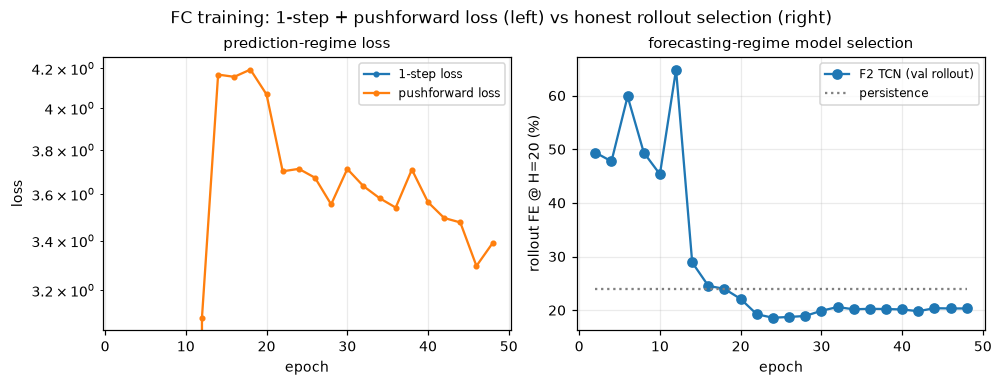

[fig] training curves -> FC_curves.png
 ep     loss     pf      fe  fe_per     gain
  2 -85.2380 0.0000 49.3951 23.9879 -51.4368
  4 -87.0145 0.0000 47.7562 23.9879 -49.7702
  6 -87.3957 0.0000 59.8601 23.9879 -59.9268
  8 -87.7121 0.0000 49.3980 23.9879 -51.4396
 10 -88.0470 0.0000 45.3476 23.9879 -47.1023
 12 -85.6597 3.0938 64.8644 23.9879 -63.0184
 14 -82.0737 4.1679 28.9101 23.9879 -17.0261
 16 -84.1304 4.1566 24.5380 23.9879  -2.2421
 18 -84.5300 4.1938 23.9802 23.9879   0.0318
 20 -87.3134 4.0678 22.1040 23.9879   8.5226
 22 -86.5446 3.7021 19.2515 23.9879  24.6025
 24 -86.2522 3.7132 18.6004 23.9879  28.9640
 26 -87.7615 3.6731 18.7448 23.9879  27.9708
 28 -87.1868 3.5549 18.9289 23.9879  26.7259
 30 -88.0350 3.7127 19.8983 23.9879  20.5523
 32 -89.0078 3.6355 20.5921 23.9879  16.4906
 34 -89.3083 3.5822 20.1729 23.9879  18.9114
 36 -89.1944 3.5410 20.2605 23.9879  18.3972
 38 -88.8455 3.7100 20.2229 23.9879  18.6173
 40 -89.9363 3.5646 20.1423 23.9879  19.0920
 42 -89.7375 3.4

In [3]:
# ============================================================================
# CELL 3 · training: F1 MECH + F3 ESN (closed form) + F2 TCN (pushforward)
# ----------------------------------------------------------------------------
# Decisions:
#  * training loss = masked weighted |dz| (residual over persistence), nbub L2
#    (mean regression anticipates rare events; the median suppresses them) -
#    PLUS a quiescence penalty: windows whose next 30 steps stay bubble-free
#    get an extra L1 term on the nbub residual. v1's over-firing (false
#    nucleation rate 1.0) is paid for here, in training;
#  * v2 PUSHFORWARD training for the TCN: after PUSH_WARM epochs of pure 1-step
#    (teacher-forced) training, each batch additionally unrolls K steps feeding
#    the model its OWN predictions back (K ramping 1 -> PUSH_KMAX). The rollout
#    is trained, not just watched - the v1 decoupling (1-step loss down,
#    rollout flat) is addressed at the loss level;
#  * model selection = multi-step ROLLOUT error on val (the FORECASTING regime,
#    teacher-free) - early stopping and the saved checkpoint both follow the
#    task we actually care about;
#  * every eval prints FE next to persistence's FE on the same starts, so
#    "did we learn anything beyond persistence" is visible at every glance;
#  * weight EMA (decoder-notebook convention) with bias correction; the best
#    EMA weights are what gets saved.
# ============================================================================
import matplotlib.pyplot as plt
from collections import defaultdict

plt.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'axes.titlesize': 10,
                     'savefig.dpi': CFG['DPI'], 'axes.grid': True, 'grid.alpha': 0.25})

# ---- quick val rollouts (shared by all training-time evals) --------------------
VA_STARTS_MID = eval_starts('val', CFG['EVAL_STRIDE'], CFG['EVAL_MAX_STARTS'], H_MID)
assert VA_STARTS_MID, 'no val rollout starts - shorten H_MID or EVAL_STRIDE'
_n_cap = max(1, CFG['QUICK_VAL_STARTS'] // max(len(MODEL_NAMES_TMP := ['x']), 1))
_sel = (np.linspace(0, len(VA_STARTS_MID) - 1,
                    min(len(VA_STARTS_MID), CFG['QUICK_VAL_STARTS'])).astype(int)
        if len(VA_STARTS_MID) > CFG['QUICK_VAL_STARTS'] else
        np.arange(len(VA_STARTS_MID)))
VA_STARTS_MID = [VA_STARTS_MID[k] for k in _sel]
VA_XZ_MID = np.stack([ZC[s['rows']] for s in VA_STARTS_MID])
VA_XC_MID = np.stack([CASE_Z[s['rows'][-1]] for s in VA_STARTS_MID])
VA_FUT_MID = np.stack([ZC[s['fut']] for s in VA_STARTS_MID])

def quick_val(step_fn):
    errs, per = [], []
    for i in range(len(VA_STARTS_MID)):
        preds, _ = rollout(step_fn, VA_XZ_MID[i], VA_XC_MID[i], H_MID)
        errs.append(fe_curve(preds, VA_FUT_MID[i]))
        pp, _ = rollout(PERSIST_STEP, VA_XZ_MID[i], VA_XC_MID[i], H_MID)
        per.append(fe_curve(pp, VA_FUT_MID[i]))
    return float(np.mean(errs)), float(np.mean(per))

# ============================== F1 · mechanism-based hybrid =====================
MBH_MODEL = fit_mbh()
F1_STEP = make_step_fn('F1 MECH', mbh=MBH_MODEL)
_e_f1, _e_p = quick_val(F1_STEP)
print(f"[f1] mechanism hybrid fitted (S*={MBH_MODEL.S_abs:.2f}, "
      f"{int((MBH_MODEL.A_quiet.shape[0]))} features/regime)")
print(f"[f1] val rollout H={H_MID}: MECH {100*_e_f1:.1f}%  vs persistence {100*_e_p:.1f}%")

# ============================== F3 · ESN ========================================
t0 = time.time()
ESN_MODEL = ESN(CFG['ESN_SIZE'], CFG['ESN_RADIUS'], CFG['ESN_LEAK'],
                CFG['ESN_ISCALE'], CFG['ESN_LAMBDA']).fit(
    TR_XZ.numpy()[:], TR_XC.numpy()[:], TR_YT.numpy())
F3_STEP = make_step_fn('F3 ESN', esn=ESN_MODEL)
_e_f3, _ = quick_val(F3_STEP)
print(f"[f3] ESN fitted ({CFG['ESN_SIZE']} units, radius {CFG['ESN_RADIUS']}, "
      f"leak {CFG['ESN_LEAK']}) in {time.time()-t0:.0f}s")
print(f"[f3] val rollout H={H_MID}: ESN {100*_e_f3:.1f}%  vs persistence {100*_e_p:.1f}%")

# ============================== F2 · TCN (pushforward) ==========================
class EMA:
    """evaluated with averaged weights, trained with raw ones (bias-corrected)."""
    def __init__(self, model, decay):
        self.dec, self.k = decay, 0
        self.init = {n: p.detach().clone() for n, p in model.named_parameters()}
        self.shadow = {n: p.detach().clone() for n, p in model.named_parameters()}
    @torch.no_grad()
    def update(self, model):
        self.k += 1
        for n, p in model.named_parameters():
            self.shadow[n].mul_(self.dec).add_(p.detach(), alpha=1 - self.dec)
    def corrected(self):
        if self.k == 0:
            return {n: t.cpu().clone() for n, t in self.init.items()}
        c = self.dec ** self.k
        return {n: ((t - c * self.init[n]) / (1 - c)).cpu()
                for n, t in self.shadow.items()}
    @torch.no_grad()
    def apply(self, model, w):
        for n, p in model.named_parameters():
            p.copy_(w[n].to(p.device))

def loss_fn(pred_dz, tgt_dz, quiescent_mask=None):
    """L1 (median regression) everywhere EXCEPT nbub, which gets L2 (mean
    regression). The mean anticipates rare events - the median suppresses them.
    QUIESCENCE PENALTY (v2): on windows whose next 30 steps stay bubble-free,
    an extra L1 term on the nbub residual pulls the net toward NOT nucleating -
    the brake v1 lacked (its false-nucleation rate was 1.0)."""
    l = (pred_dz - tgt_dz).abs() * WL_T
    out = l.mean()
    nb_cols = [LIVE_COLS.index(c) for c in GROUPS.get('nbub', [])]
    if nb_cols:
        m = torch.zeros(L, device=pred_dz.device)
        m[nb_cols] = 1.0
        n = max(m.sum(), 1e-9)
        out = out - (l * m).sum() / n \
              + (((pred_dz - tgt_dz) ** 2) * WL_T * m).sum() / n
    if quiescent_mask is not None and nb_cols and float(quiescent_mask.sum()) > 0:
        q = quiescent_mask.float().view(-1, 1)
        out = out + CFG['LOSS_W'].get('nbub', 6.0) * \
              (((pred_dz - tgt_dz).abs() * WL_T * q)[:, nb_cols].sum()
               / max(float(q.sum()) * len(nb_cols), 1e-9))
    return out

def lr_at(ep):
    w_ = max(CFG['WARMUP_EPOCHS'], 1)
    if ep <= w_:
        return CFG['LR'] * ep / w_
    lo = CFG['LR'] / 20.0
    return lo + (CFG['LR'] - lo) * 0.5 * (1 + math.cos(math.pi * (ep - w_)
                                                   / max(CFG['EPOCHS'] - w_, 1)))

HIST, BEST = {}, {}
TR_DS = torch.utils.data.TensorDataset(TR_XZ, TR_XC, TR_YT)

# ---- onset-augmented sampling + quiescence labels (rare-event balancing) ------
# onset steps are ~1/70 of the data; without reweighting the learned models
# majority-fit the smooth in-burst dynamics and never learn nucleation. Windows
# are weighted by proximity to the next 0->1 rise of nbub (training data only).
# QUIESCENT windows (no bubble in the next 30 steps) carry the penalty label.
_nbj = LIVE_COLS.index('nbub') if 'nbub' in LIVE_COLS else None
if _nbj is not None:
    _nb_phys = ROWS['nbub'].values
    w = np.ones(len(TR_X), np.float64)
    QUI = np.zeros(len(TR_X), bool)                       # quiescent-label mask
    for i, y_row in enumerate(TR_Y):
        stem = ROWS.iat[int(y_row), ROWS.columns.get_loc('file')]
        p_y = int(ROWS.iat[int(y_row), ROWS.columns.get_loc('pos')])
        p_end = p_y - 1                                    # window end (local)
        if _nb_phys[int(y_row)] >= 1.0 and _nb_phys[FILE_ROWS[stem][p_end]] < 1.0:
            w[i] = 8.0                                     # the onset step itself
        else:
            fr = FILE_ROWS[stem]
            ahead = _nb_phys[fr[p_end + 1: p_end + 31]]    # next 30 steps
            on = np.where(ahead >= 1.0)[0]
            d = int(on[0]) + 1 if len(on) else 999         # steps until onset
            if 2 <= d <= 12:
                w[i] = 4.0                                 # approaching onset
            elif d == 999 and _nb_phys[FILE_ROWS[stem][p_end]] < 1.0:
                QUI[i] = True                              # stays quiet -> penalty on
    sampler = torch.utils.data.WeightedRandomSampler(
        torch.from_numpy(w), num_samples=len(TR_X), replacement=True)
    dl_tcn = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(TR_XZ, TR_XC, TR_YT,
                                       torch.from_numpy(QUI.astype(np.float32))),
        batch_size=CFG['BATCH'], sampler=sampler)
    print(f"[train] onset-augmented sampling: {int((w == 8).sum())} onset windows "
          f"(x8), {int((w == 4).sum())} pre-onset (x4), {int(QUI.sum())} quiescent "
          f"(penalty on), {int((w == 1).sum())} bulk (x1)")
else:
    dl_tcn = torch.utils.data.DataLoader(TR_DS, batch_size=CFG['BATCH'], shuffle=True)

# ---- pushforward machinery -------------------------------------------------------
def pushforward_batch(net, xz_b, xc_b, k):
    """unroll k steps feeding the model its own predictions back; ground truth
    targets come from pre-extracted continuation rows. Returns (preds, tgts)
    aligned arrays of shape (B, k, L). Batches are built so that every sample's
    k continuation rows are contiguous in the SAME file (one experiment)."""
    B = xz_b.size(0)
    z = xz_b.clone()                                       # (B, WIN, L)
    preds = torch.empty((B, k, L), device=xz_b.device)
    for s in range(k):
        x = torch.cat([z, xc_b[:, None].expand(-1, z.size(1), -1)], -1)
        dz = net(x)                                        # (B, L)
        zt = z[:, -1] + dz
        zt = torch.max(torch.min(zt, torch.from_numpy(Z_HI).to(zt.device)),
                       torch.from_numpy(Z_LO).to(zt.device))
        preds[:, s] = zt
        z = torch.cat([z[:, 1:], zt[:, None]], 1)          # slide with OWN prediction
    return preds

# continuation rows for pushforward: for each train sample i, the PUSH_KMAX
# rows AFTER its target (contiguous inside the file+region by construction).
_CONT = np.full((len(TR_X), CFG['PUSH_KMAX']), -1, np.int64)
if _nbj is not None or True:
    for i in range(len(TR_X)):
        y_row = int(TR_Y[i])
        stem = ROWS.iat[y_row, ROWS.columns.get_loc('file')]
        p_y = int(ROWS.iat[y_row, ROWS.columns.get_loc('pos')])
        rb = region_bounds(stem, 'train')
        fr = FILE_ROWS[stem]
        for s in range(CFG['PUSH_KMAX']):
            p = p_y + s + 1
            if p < rb[1]:
                _CONT[i, s] = fr[p]
_cont_t = torch.from_numpy(ZC[_CONT].astype(np.float32)) if _CONT.max() >= 0 else None
# rows with -1 index would read garbage; guard by a validity mask instead
_cont_valid = torch.from_numpy((_CONT >= 0).all(1)).to(DEVICE) \
    if _CONT.max() >= 0 else None
if _cont_t is not None:
    _cont_t[_CONT < 0] = 0.0                               # neutral fill; masked in loss

name = 'F2 TCN'
net = net_tcn
ema = EMA(net, 0.999)
opt = torch.optim.AdamW(net.parameters(), lr=CFG['LR'],
                        weight_decay=CFG['WEIGHT_DECAY'])
hist, best, best_ep, bad, t0 = [], float('inf'), -1, 0, time.time()
n_par = sum(p.numel() for p in net.parameters())
print(f"\n[{name}] params {n_par/1e3:.0f} k | {len(dl_tcn)} steps/epoch | up to "
      f"{CFG['EPOCHS']} epochs (patience {CFG['PATIENCE']}) | pushforward "
      f"warm {CFG['PUSH_WARM']} ep, K 1->{CFG['PUSH_KMAX']}")
for ep in range(1, CFG['EPOCHS'] + 1):
    for g in opt.param_groups:
        g['lr'] = lr_at(ep)
    net.train()
    run, nb = defaultdict(float), 0
    k_push = 1 if ep <= CFG['PUSH_WARM'] else min(CFG['PUSH_KMAX'], 1 + (ep - CFG['PUSH_WARM']))
    for xz_b, xc_b, y_b, qui_b in dl_tcn:
        xz_b, xc_b, y_b, qui_b = (t.to(DEVICE) for t in (xz_b, xc_b, y_b, qui_b))
        x = torch.cat([xz_b, xc_b[:, None].expand(-1, xz_b.size(1), -1)], -1)
        dz_pred = net(x)
        loss = loss_fn(dz_pred, y_b - xz_b[:, -1], quiescent_mask=qui_b.bool())
        opt.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(net.parameters(), CFG['GRAD_CLIP'])
        opt.step()
        ema.update(net)
        run['loss'] += float(loss); nb += 1
    # ---- aligned pushforward pass (own mini-corpus of rollout starts) --------
    if k_push > 1 and _cont_t is not None:
        rng = np.random.default_rng(SEED + ep)
        cand = np.where(_CONT[:, 0] >= 0)[0]
        sel = rng.choice(cand, size=min(2048, len(cand)), replace=False)
        for s0 in range(0, len(sel), CFG['BATCH']):
            sl = sel[s0: s0 + CFG['BATCH']]
            xz_b = TR_XZ[sl].to(DEVICE); xc_b = TR_XC[sl].to(DEVICE)
            tgt = _cont_t[sl].to(DEVICE)                   # (B, KMAX, L)
            preds = pushforward_batch(net, xz_b, xc_b, k_push)
            # targets for steps 1..k are the SAME rows the 1-step target came from
            loss_pf = (preds - tgt[:, :k_push]).abs().mean()
            opt.zero_grad(set_to_none=True)
            (CFG['LOSS_W'].get('pf', 1.0) * loss_pf).backward()
            nn.utils.clip_grad_norm_(net.parameters(), CFG['GRAD_CLIP'])
            opt.step()
            run['pf'] += float(loss_pf); nbs = 1
    if ep % CFG['EVAL_EVERY'] == 0 or ep == CFG['EPOCHS']:
        prev = {n: p.detach().clone() for n, p in net.named_parameters()}
        ema.apply(net, ema.corrected())
        net.eval()
        step_fn = make_step_fn(name, net=net)
        e_val, e_per = quick_val(step_fn)
        ema.apply(net, prev)
        net.train()
        hist.append(dict(ep=ep, loss=run['loss'] / nb,
                         pf=run.get('pf', 0.0) / max(1, int(run.get('pf', 0.0) > 0)),
                         fe=100 * e_val, fe_per=100 * e_per,
                         gain=100 * (e_per / e_val - 1)))
        mark = '  <- best' if e_val < best else ''
        print(f"  ep {ep:3d}  loss {run['loss']/nb:.4f}"
              + (f"  pf {run['pf']/max(1, len(sel)//CFG['BATCH']+1):.4f}" if k_push > 1 and 'pf' in run else "")
              + f" | val rollout H={H_MID} FE {100*e_val:5.2f}%  "
              f"(persistence {100*e_per:5.2f}%, +{100*(e_per/e_val-1):4.0f}%){mark}")
        if e_val < best:
            best, best_ep, bad = e_val, ep, 0
        else:
            bad += 1
            if bad >= CFG['PATIENCE']:
                print(f"  early stop (no val-rollout improvement for {bad} evals)")
                break
ema.apply(net, ema.corrected())                          # final weights = best-EMA style
HIST[name] = pd.DataFrame(hist)
BEST[name] = dict(val_fe=best, ep=best_ep, params=n_par,
                  secs=round(time.time() - t0, 1))
print(f"[{name}] best val rollout FE {100*best:.2f}% at epoch {best_ep} "
      f"({BEST[name]['secs']}s)")

# ---- training curves -----------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4), constrained_layout=True)
h = HIST['F2 TCN']
ax[0].plot(h['ep'], h['loss'], marker='.', label='1-step loss')
if (h['pf'] > 0).any():
    ax[0].plot(h['ep'], h['pf'], marker='.', label='pushforward loss')
ax[0].set_yscale('log'); ax[0].set_xlabel('epoch'); ax[0].set_ylabel('loss')
ax[0].set_title('prediction-regime loss'); ax[0].legend(fontsize=8)
ax[1].plot(h['ep'], h['fe'], marker='o', label='F2 TCN (val rollout)')
ax[1].plot(h['ep'], h['fe_per'], ls=':', color='gray', label='persistence')
ax[1].set_xlabel('epoch'); ax[1].set_ylabel(f'rollout FE @ H={H_MID} (%)')
ax[1].set_title('forecasting-regime model selection'); ax[1].legend(fontsize=8)
fig.suptitle('FC training: 1-step + pushforward loss (left) vs honest rollout selection (right)',
             fontsize=11)
fig.savefig(os.path.join(OUT_DIR, f'{PREFIX}_curves.png'))
plt.show()
print(f"[fig] training curves -> {PREFIX}_curves.png")
print(HIST['F2 TCN'].round(4).to_string(index=False))
print("[read] the right panel is the honest metric: a model can drive the 1-step loss "
      "down while the ROLLOUT degrades - selection here watches the rollout only.")
print("[read] the pushforward term (left, after warm-up) optimizes the rollout "
      "DIRECTLY: the model sees its own prediction errors compounding and learns "
      "to correct them - the v1 GRU/TRF never trained on that signal.")


## 4 · Results: why short-range forecasting works and long-range point forecasts fail

**The split in predictability is physical, not model-made.** Read the per-indicator table at
horizon 80: under *persistence itself* the thermal columns (Tmean) err at 0.3–1 %, the
hot-wall fraction at ~10 %, while the void columns reach 77–100 %, D32 54 % and the bubble
count 45 %. Two timescales coexist in the same system. The temperature field is
diffusion-dominated — it integrates smoothly and remembers its initial condition for the
whole horizon. The void geometry is set by **nucleation events**: quiescent stretches of
26–30 steps end in bursts that rearrange the gas field at once.

**Short horizons (1–20 steps) stay inside one regime stretch, and the drift is learnable.**
The mechanism model — which literally integrates superheat toward the next onset — beats
persistence one step ahead (2.9 % vs 3.9 % in the free rollout); the TCN wins at horizon 20
(34.8 % vs 40.2 %). One-step errors sit at 4–6 % for the closed-form models.

**Long horizons (40–400 steps) fail for three compounding reasons.** (i) *Timing*: the
measured onset error is ≈ 14.6 steps — half a burst period — and 63–69 % of onsets fire
early beyond the ±8-step tolerance; one mistimed burst decorrelates every void variable
after it. (ii) *Compounding*: a teacher-free rollout feeds the model its own errors;
pushforward training mitigates this but cannot remove it (the TCN still ends at 61.8 %).
(iii) *Chaos*: the floor experiment — taking the nearest *real* trajectory from another
condition as the forecast — already diverges by 45.5 % at horizon 80. Persistence (41.9 %)
stays below that floor only by predicting *no dynamics at all*: it has no events to
mis-time. Long-range point forecasting of event-driven variables is chaos-limited, not a
modelling failure. The useful long-range objects are statistical — onset timing, burst rate,
plateau levels and the spread across the ladder — which is exactly what the next section and
the scenario exports measure.

[eval] 336 test rollout starts (H_MAX=80, stride 5, cap 112/file)
[eval] F0 persistence rollouts done (2 clamped entries)
[eval] F1 MECH        rollouts done (14688 clamped entries)
[eval] F3 ESN         rollouts done (90933 clamped entries)
[eval] F2 TCN         rollouts done (164716 clamped entries)
[floor] chaotic floor (nearest-real-trajectory divergence, cross-condition analog): H1 32.3%  H80 45.5%  (the honest lower bound for point forecasts)
[pred] 1-step (prediction regime, 5907 test windows): F0 persistence 4.4%  F1 MECH 5.2%  F3 ESN 6.7%  F2 TCN 18.0%


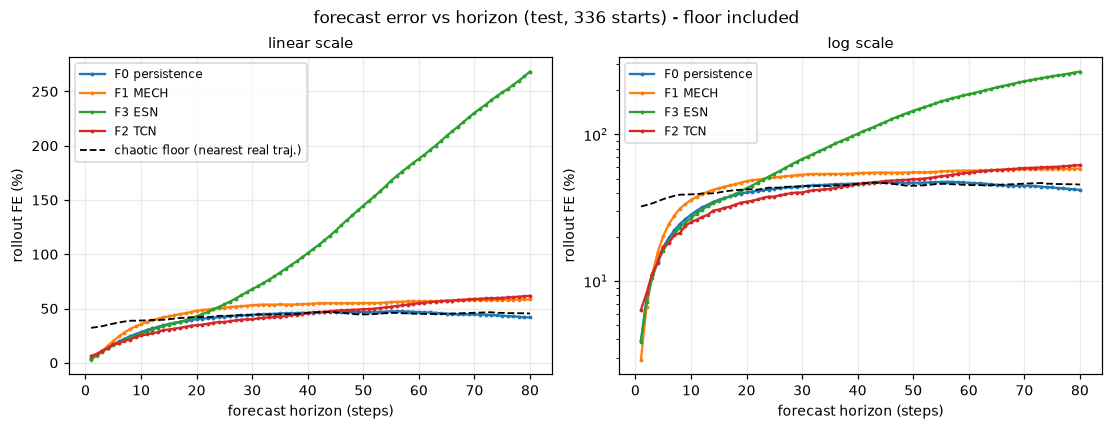

[fig] horizon curves -> FC_horizon.png

=== forecasting leaderboard (FE = mean |err| over live cols, z-units %) ===
                  pred1  fore1     H20     H80   avgH   medH   p90H blow  clamp
------------------------------------------------------------------------------------
F0 persistence      4.4    3.9    40.2    41.9   40.5   35.3   87.8    0      2
F1 MECH             5.2    2.9    48.0    58.4   49.4   54.0   84.2    0  14688
F3 ESN              6.7    3.8    43.0   268.4  118.6  308.8  446.8    0  90933
F2 TCN             18.0    6.4    34.8    61.8   43.3   49.5  123.0    0 164716
[read] pred1 = prediction regime (teacher-forced); fore/H* = forecasting regime (teacher-free rollout); H* is the value AT that horizon, avgH the mean over the whole 1..80 rollout.
[read] avgH is the honest summary when the system is CYCLIC: a point-at-H value can reward persistence by accident (error dips when the cycle returns to the start state); the horizon-mean cannot.

[per-indicator FE @ H

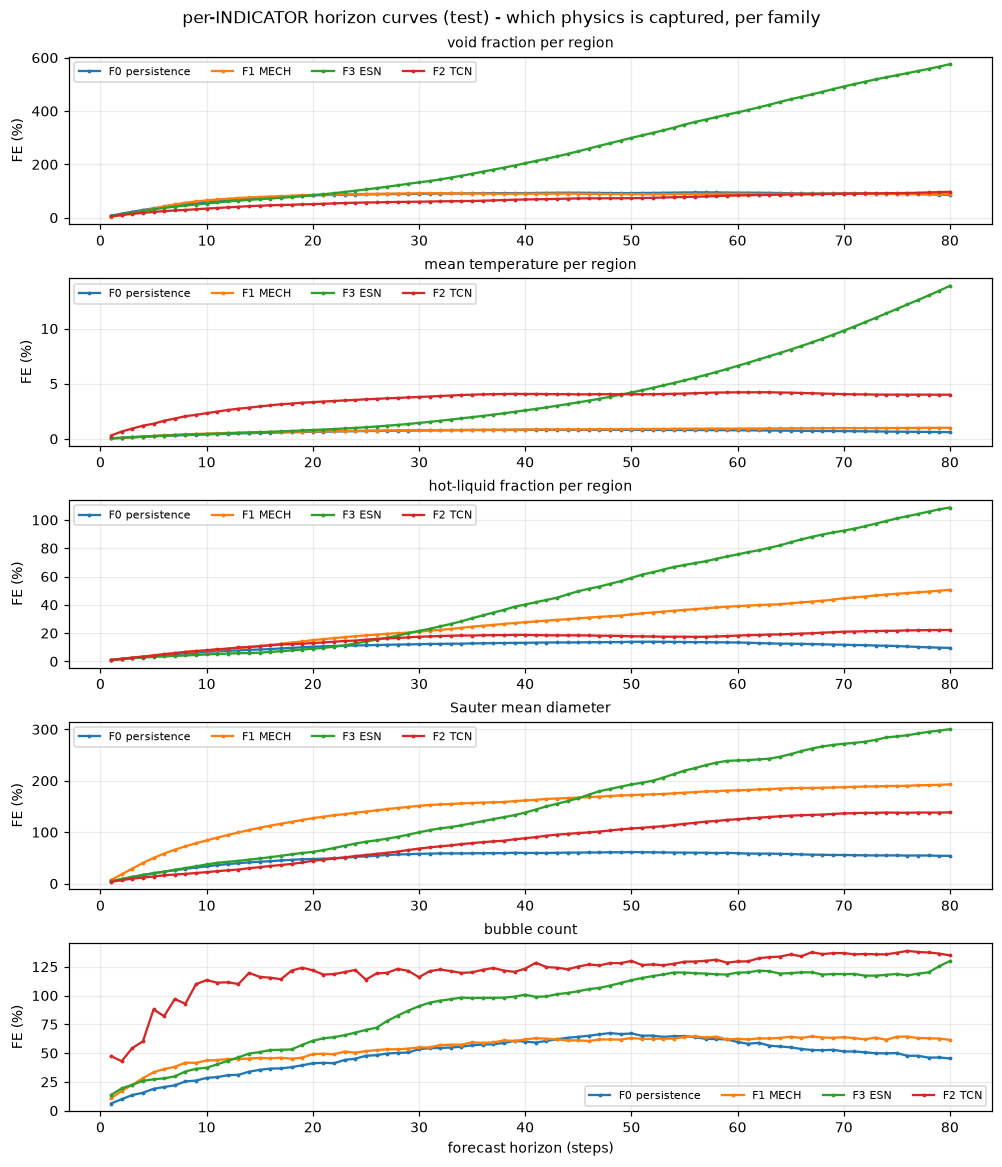

[fig] per-indicator horizon curves -> FC_percol_horizon.png

[per-family mean rollout FE (1..H), %]
        n_cols  F0 persistence  F1 MECH  F3 ESN  F2 TCN
family                                                 
alpha        5            82.5     81.8   247.2    65.0
Tmean        5             0.7      0.8     4.2     3.6
f_hot        1            10.9     27.1    45.3    15.9
D32          1            51.1    147.5   151.0    83.8
nbub         1            48.7     54.9    89.2   120.4
[read] a model wins on average but loses on nbub? this table is where that is visible: the aggregate leaderboard cannot show it.

=== physics checks (forecasting regime, test) ===
                thermal_trend_acc  D32_err_px  nbub_MAE  alpha_in_bounds  gas_gen_ratio
F0 persistence              0.016       6.426     0.807              1.0          0.000
F1 MECH                     0.557      18.537     0.911              1.0         -1.974
F3 ESN                      0.520      18.975     1.480         

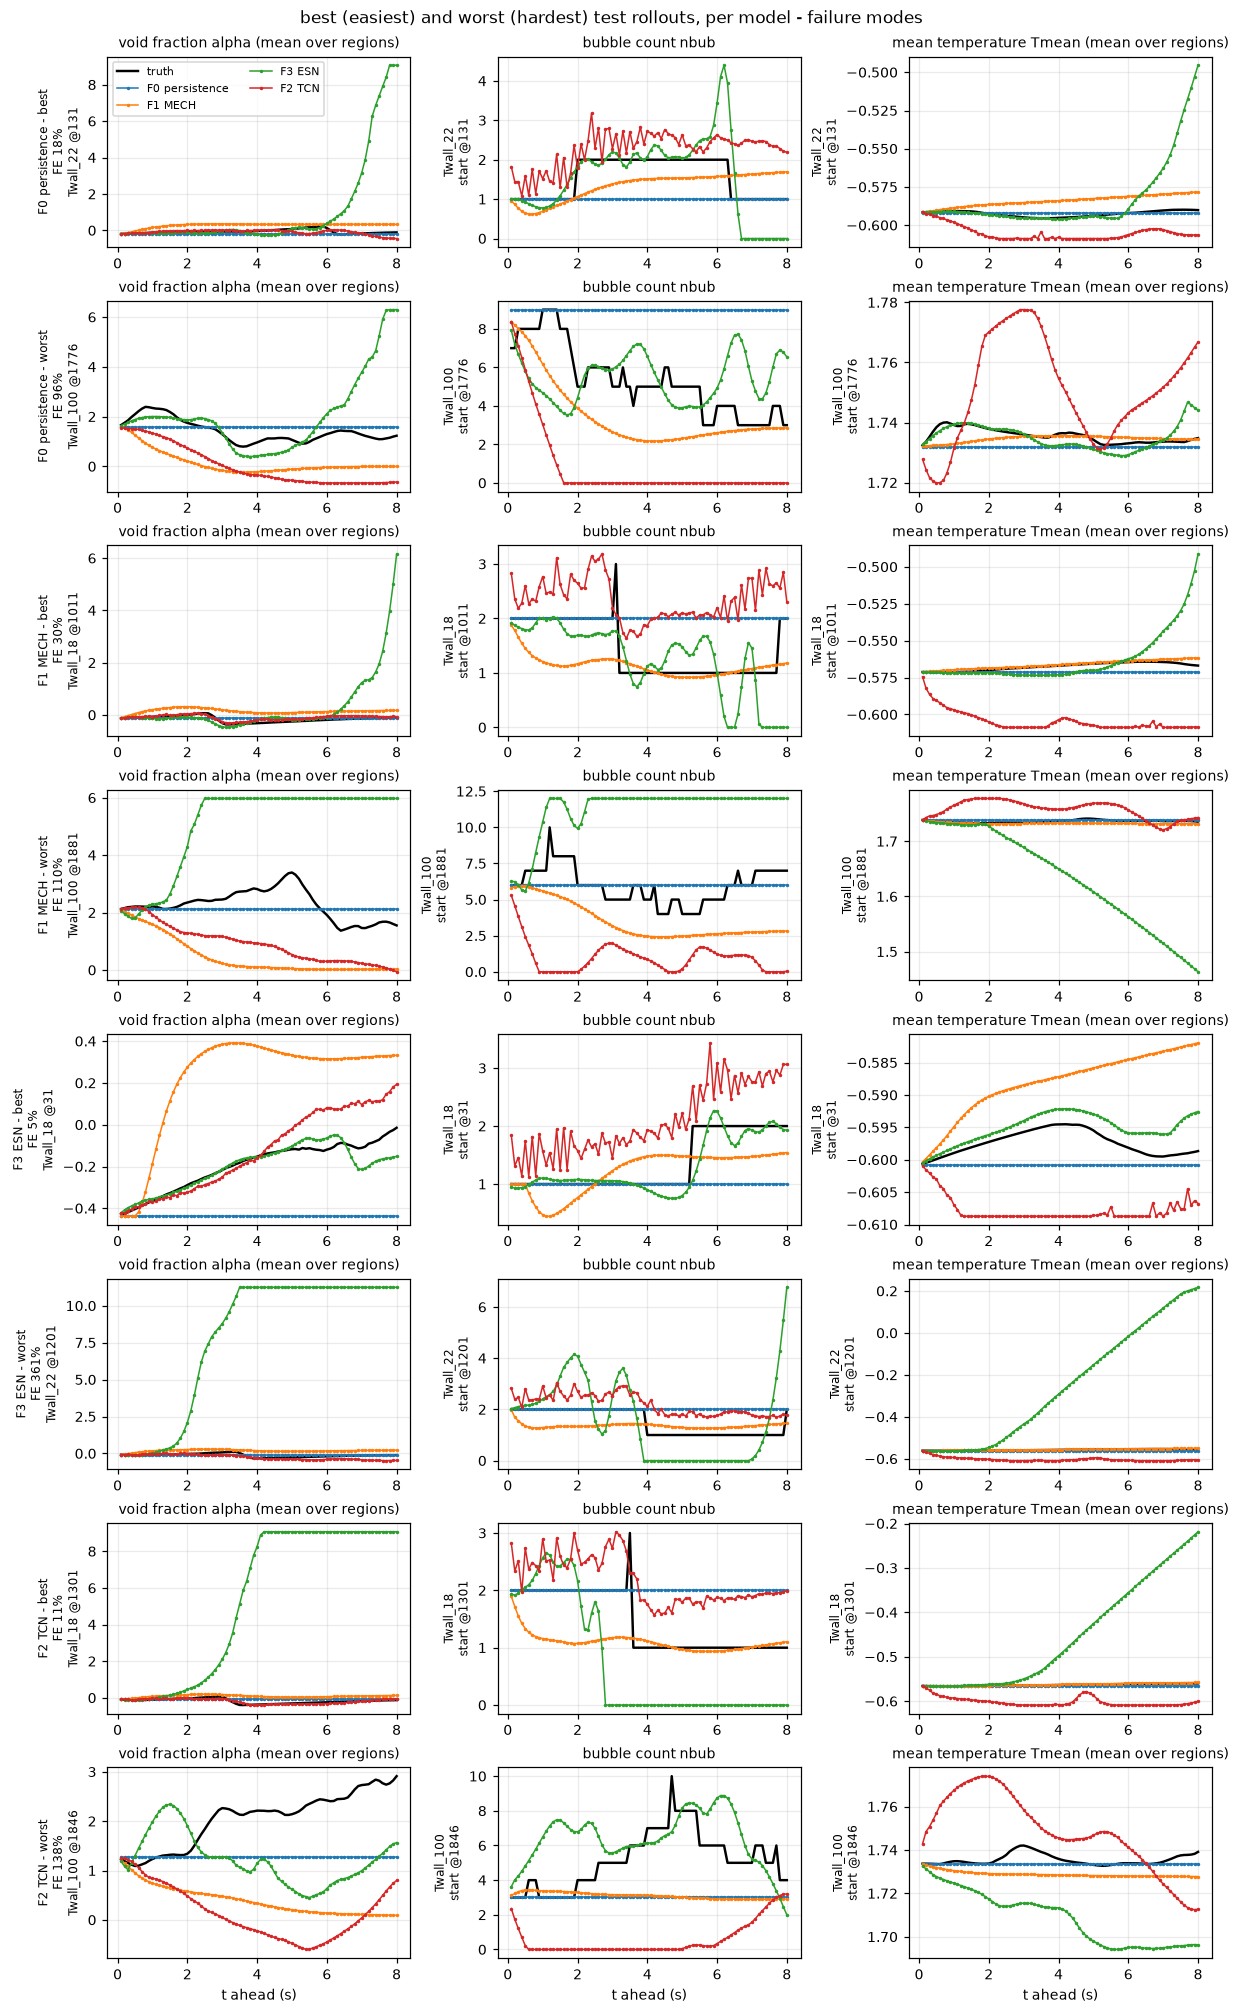

[fig] best/worst example trajectories -> FC_bestworst.png
[read] the 'best' row is often a quiescent or smoothly-relaxing start (where persistence also shines); the 'worst' row is where the burst timing is missed - compare the nbub column across rows to see each model's failure signature.


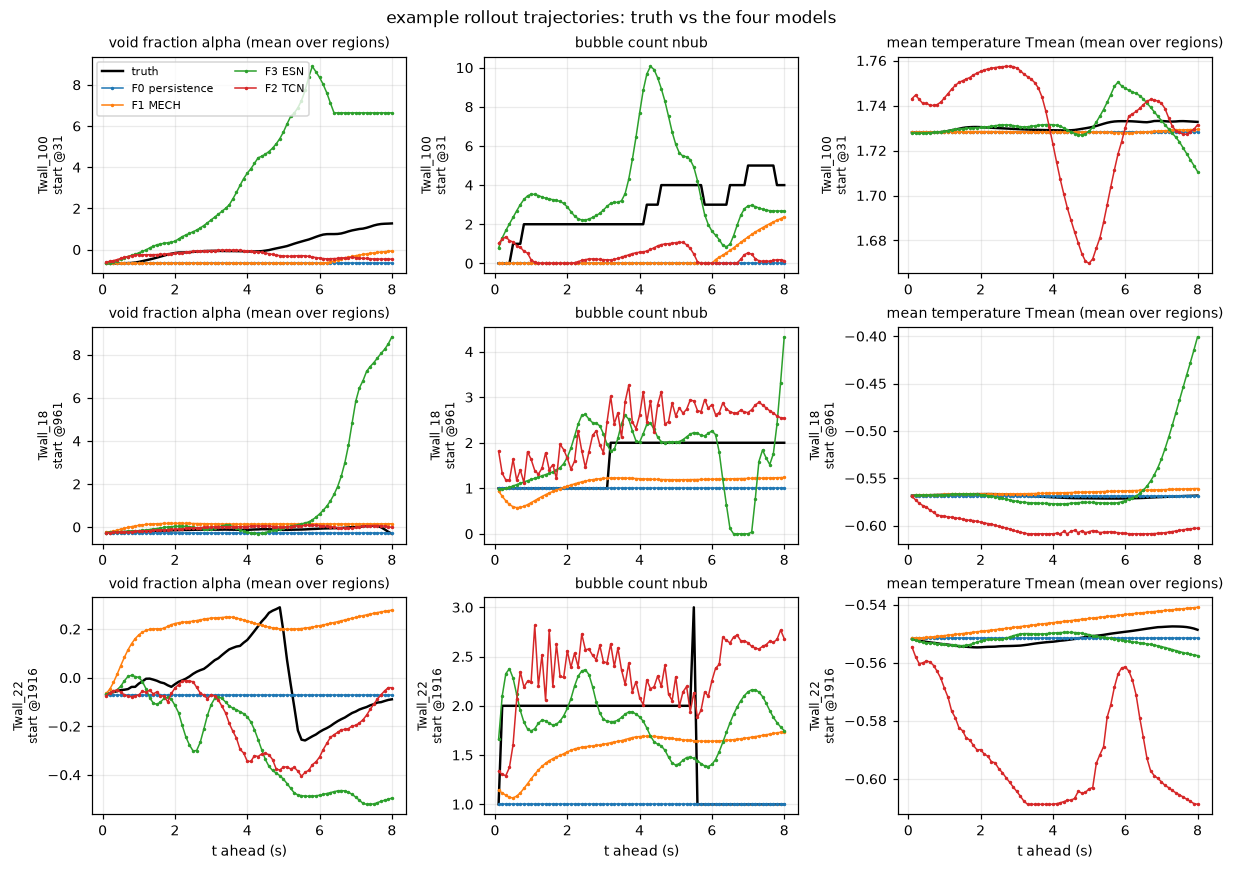

[fig] example trajectories -> FC_examples.png
[read] the nbub column is where nucleation lives: the count must RISE from quiescence at roughly the right time - the next cell measures exactly that.


In [4]:
# ============================================================================
# CELL 4 · full evaluation: leaderboard, horizon curves, chaotic floor,
#          per-INDICATOR analysis, physics checks, per-file table,
#          best/worst example trajectories
# ----------------------------------------------------------------------------
# Protocol (mirrors the dataset authors):
#  * PREDICTION regime: 1-step error over ALL test windows (teacher-forced);
#  * FORECASTING regime: teacher-free rollout to H_MAX from spaced test starts;
#  * robust stats (median / p90 / blow-up counts) so means cannot hide failures;
#  * physics-based metrics: thermal-trend consistency (Tmean), interface geometry
#    (D32, nbub), gas-fraction boundedness + generation-rate (alpha);
#  * a CHAOTIC FLOOR: divergence of the nearest real (pre-onset) trajectory from
#    the truth - the honest lower bound for any point forecaster in this system;
#  * v2 PER-INDICATOR analysis: each of the 17 indicators gets its own horizon
#    curve and its own leaderboard row-group, so "which physics is captured"
#    (thermal vs void vs geometry) is answered per column, not just on average;
#  * v2 BEST/WORST examples: for every model the 2 easiest and 2 hardest test
#    starts (by that model's own mean rollout FE) are shown - the failure modes
#    are where the improvement lives.
# ============================================================================
import numpy as np, pandas as pd

# ---- the four models, final weights --------------------------------------------
STEPS = {'F0 persistence': PERSIST_STEP, 'F1 MECH': F1_STEP,
         'F3 ESN': F3_STEP}
STEPS['F2 TCN'] = make_step_fn('F2 TCN', net=net_tcn)
MODELS = list(STEPS)

# ---- rollout cache over test starts --------------------------------------------
TE_STARTS = eval_starts('test', CFG['EVAL_STRIDE'], CFG['EVAL_MAX_STARTS'], H_MAX)
assert TE_STARTS, 'no test rollout starts - shorten H_MAX'
TE_XZ = np.stack([ZC[s['rows']] for s in TE_STARTS])
TE_XC = np.stack([CASE_Z[s['rows'][-1]] for s in TE_STARTS])
TE_FUT = np.stack([ZC[s['fut']] for s in TE_STARTS])
print(f"[eval] {len(TE_STARTS)} test rollout starts (H_MAX={H_MAX}, "
      f"stride {CFG['EVAL_STRIDE']}, cap {CFG['EVAL_MAX_STARTS']}/file)")

ROLL = {}                                     # name -> (n_starts, H_MAX, L) preds
NCLAMP = {}
for name in MODELS:
    preds = np.empty((len(TE_STARTS), H_MAX, L), np.float32)
    ncl = 0
    for i in range(len(TE_STARTS)):
        preds[i], k = rollout(STEPS[name], TE_XZ[i], TE_XC[i], H_MAX)
        ncl += k
    ROLL[name] = preds
    NCLAMP[name] = ncl
    print(f"[eval] {name:14s} rollouts done ({ncl} clamped entries)")

# ---- chaotic floor: nearest-real-trajectory (cross-condition analog) ----------
# v3: test files share no timeline with train/val, so the "nearest real
# trajectory" is looked up ACROSS files: the continuation of the most similar
# train/val window is used as the forecast (an analog / Lorenz-style
# forecaster). Its error is the honest lower bound for any point forecaster
# that must generalize to unseen conditions.
trn_rows = np.where(ROWS.split.isin(['train', 'val']).values)[0]
TR_Z = ZC[trn_rows]
def chaos_floor(starts, xz, fut):
    fl = np.zeros((len(starts), fut.shape[1]), np.float32)
    for i in range(len(starts)):
        d = np.linalg.norm(TR_Z - xz[i].mean(0), axis=1)
        order = np.argsort(d)
        fl[i] = np.nan
        for r in order[:200]:          # first candidate with a long-enough continuation
            rr = trn_rows[r]
            p0 = int(ROWS.iat[rr, ROWS.columns.get_loc('pos')])
            fr = FILE_ROWS[ROWS.iat[rr, ROWS.columns.get_loc('file')]]
            if p0 + fut.shape[1] > len(fr):
                continue
            fl[i] = fe_curve(ZC[fr[p0: p0 + fut.shape[1]]], fut[i])
            break
    return fl

FLOOR_CURVE = np.nanmean(chaos_floor(TE_STARTS, TE_XZ, TE_FUT), 0)
print(f"[floor] chaotic floor (nearest-real-trajectory divergence, cross-condition "
      f"analog): H1 {100*FLOOR_CURVE[0]:.1f}%  H{H_MAX} {100*FLOOR_CURVE[-1]:.1f}%  "
      "(the honest lower bound for point forecasts)")

# ---- prediction regime: 1-step over ALL test windows ---------------------------
one_step = {}
if TE_X is not None:
    Xz = ZC[TE_X]; Xc = CASE_Z[TE_X[:, -1]]; Yz = ZC[TE_Y]
    for name in MODELS:
        dz = np.empty((len(Xz), L), np.float32)
        for i in range(0, len(Xz), 256):
            sl = slice(i, min(i + 256, len(Xz)))
            if name == 'F0 persistence':
                dz[sl] = 0.0
            elif name == 'F1 MECH':
                for k in range(sl.start, sl.stop):
                    dz[k] = MBH_MODEL.step_dz(Xz[k], Xc[k])
            elif name == 'F3 ESN':
                for k in range(sl.start, sl.stop):
                    dz[k] = ESN_MODEL.step_dz(Xz[k], Xc[k])
            else:
                xb = torch.from_numpy(np.concatenate(
                    [Xz[sl], np.tile(Xc[sl][:, None], (1, WIN, 1))], -1)).to(DEVICE)
                with torch.no_grad():
                    dz[sl] = net_tcn(xb).cpu().numpy()
        preds = Xz[:, -1] + dz                            # prediction = last state + residual
        one_step[name] = 100 * float(np.mean(np.abs(preds - Yz) * WL[None]) / WL.mean())
print(f"[pred] 1-step (prediction regime, {len(TE_X)} test windows): "
      + "  ".join(f"{k} {v:.1f}%" for k, v in one_step.items()))

# ---- horizon curves + figure ----------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8), constrained_layout=True)
hs = np.arange(1, H_MAX + 1)
for name in MODELS:
    fe = np.mean([fe_curve(ROLL[name][i], TE_FUT[i]) for i in range(len(TE_STARTS))], 0)
    ax[0].plot(hs, 100 * fe, marker='.', ms=3, label=name)
    ax[1].plot(hs, 100 * fe, marker='.', ms=3, label=name)
ax[0].plot(hs, 100 * FLOOR_CURVE, 'k--', lw=1.2, label='chaotic floor (nearest real traj.)')
ax[1].plot(hs, 100 * FLOOR_CURVE, 'k--', lw=1.2)
ax[1].set_yscale('log')
for a, t in ((ax[0], 'linear scale'), (ax[1], 'log scale')):
    a.set_xlabel('forecast horizon (steps)'); a.set_ylabel('rollout FE (%)')
    a.set_title(t); a.legend(fontsize=8)
fig.suptitle(f'forecast error vs horizon (test, {len(TE_STARTS)} starts) - floor included', fontsize=11)
fig.savefig(os.path.join(OUT_DIR, f'{PREFIX}_horizon.png'))
plt.show()
print(f"[fig] horizon curves -> {PREFIX}_horizon.png")

# ---- leaderboard ----------------------------------------------------------------
def fe_curves(name):
    """per-start FE curves (H_MAX,)."""
    return np.array([fe_curve(ROLL[name][i], TE_FUT[i]) for i in range(len(TE_STARTS))])

FE_CURVES = {name: fe_curves(name) for name in MODELS}

def stats_at(name, h):
    """per-start FE at horizon h -> summary stats."""
    k = min(h, H_MAX) - 1
    es = FE_CURVES[name][:, k]
    med = float(np.median(es))
    return es, med

lead = []
for name in MODELS:
    es1 = np.abs((ROLL[name][:, 0]) - TE_FUT[:, 0]).mean(1)          # H=1 rollout FE
    esH, medH = stats_at(name, H_MAX)
    esM, medM = stats_at(name, H_MID)
    avgH = FE_CURVES[name].mean()                                     # mean over 1..H_MAX
    lead.append(dict(model=name,
                     pred1=one_step.get(name, float('nan')),
                     fore1=100 * float(es1.mean()),
                     **{f'H{H_MID}': 100 * float(esM.mean())},
                     **{f'H{H_MAX}': 100 * float(esH.mean())},
                     avgH=100 * float(avgH),
                     medH=100 * medH, p90H=100 * float(np.percentile(esH, 90)),
                     blowups=int((esH > CFG['BLOWUP_K'] * max(medH, 1e-9)).sum()),
                     clamped=int(NCLAMP[name])))
LEAD = pd.DataFrame(lead).set_index('model')
print(f"\n=== forecasting leaderboard (FE = mean |err| over live cols, z-units %) ===")
print(f"{'':16s} {'pred1':>6s} {'fore1':>6s} {'H'+str(H_MID):>7s} {'H'+str(H_MAX):>7s} "
      f"{'avgH':>6s} {'medH':>6s} {'p90H':>6s} {'blow':>4s} {'clamp':>6s}")
print("-" * 84)
for m, r in LEAD.iterrows():
    print(f"{m:16s} {r['pred1']:6.1f} {r['fore1']:6.1f} {r[f'H{H_MID}']:7.1f} "
          f"{r[f'H{H_MAX}']:7.1f} {r['avgH']:6.1f} {r['medH']:6.1f} {r['p90H']:6.1f} "
          f"{int(r['blowups']):4d} {int(r['clamped']):6d}")
print(f"[read] pred1 = prediction regime (teacher-forced); fore/H* = forecasting regime "
      f"(teacher-free rollout); H* is the value AT that horizon, avgH the mean over the "
      f"whole 1..{H_MAX} rollout.")
print("[read] avgH is the honest summary when the system is CYCLIC: a point-at-H value "
      "can reward persistence by accident (error dips when the cycle returns to the "
      "start state); the horizon-mean cannot.")
LEAD.to_csv(os.path.join(OUT_DIR, f'{PREFIX}_leaderboard.csv'))

# ============================== v2: PER-INDICATOR analysis =====================
# Every indicator gets: its own FE-at-H_MAX value per model, its own horizon
# curve (grouped figure), and a group summary (void / thermal / hot-fraction /
# geometry). The question "which physics did each model capture" is answered
# per column instead of on the 17-column average.
# ================================================================================
PERCOL_H = {name: np.abs(ROLL[name] - TE_FUT).mean(0) for name in MODELS}   # (H_MAX, L)
pc = []
for j, c in enumerate(LIVE_COLS):
    row = {'col': c}
    for name in MODELS:
        row[name] = 100 * float(PERCOL_H[name][H_MAX - 1, j])
    pc.append(row)
PC = pd.DataFrame(pc).set_index('col')
WCOLS = (PC[MODELS].mean(1).sort_values(ascending=False))
print("\n[per-indicator FE @ H_MAX, %] (sorted by mean across models)")
print(PC.loc[WCOLS.index].round(1).to_string())
PC.to_csv(os.path.join(OUT_DIR, f'{PREFIX}_percol.csv'))
print("[read] the D32/nbub rows are the interface-geometry story; alpha rows the "
      "void-fraction story; Tmean rows the thermal story.")

# ---- per-indicator horizon curves, grouped by physics family -------------------
FAMILIES = [('alpha', 'void fraction per region'),
            ('Tmean', 'mean temperature per region'),
            ('f_hot', 'hot-liquid fraction per region'),
            ('D32', 'Sauter mean diameter'),
            ('nbub', 'bubble count')]
fig, axes = plt.subplots(len(FAMILIES), 1, figsize=(9, 2.1 * len(FAMILIES)),
                         constrained_layout=True)
fam_tab = []
for r_, (pref, ttl) in enumerate(FAMILIES):
    cols = [j for j, c in enumerate(LIVE_COLS)
            if c == pref or c.startswith(pref + '_')]
    if not cols:
        axes[r_].set_axis_off(); continue
    ax = axes[r_]
    for name in MODELS:
        fe = PERCOL_H[name][:, cols].mean(1)
        ax.plot(hs, 100 * fe, marker='.', ms=3, label=name)
    ax.set_title(ttl, fontsize=9); ax.legend(fontsize=7, ncol=4)
    if r_ == len(FAMILIES) - 1: ax.set_xlabel('forecast horizon (steps)')
    ax.set_ylabel('FE (%)')
    row = {'family': pref, 'n_cols': len(cols)}
    for name in MODELS:
        row[name] = 100 * float(PERCOL_H[name][:, cols].mean())
    fam_tab.append(row)
fig.suptitle('per-INDICATOR horizon curves (test) - which physics is captured, per family',
             fontsize=11)
fig.savefig(os.path.join(OUT_DIR, f'{PREFIX}_percol_horizon.png'))
plt.show()
print(f"[fig] per-indicator horizon curves -> {PREFIX}_percol_horizon.png")
FAM = pd.DataFrame(fam_tab).set_index('family')
print("\n[per-family mean rollout FE (1..H), %]")
print(FAM.round(1).to_string())
FAM.to_csv(os.path.join(OUT_DIR, f'{PREFIX}_perfam.csv'))
print("[read] a model wins on average but loses on nbub? this table is where that "
      "is visible: the aggregate leaderboard cannot show it.")

# ---- physics checks (indicator analogues of the authors' metrics) -----------------
def physics_checks(name):
    P = ROLL[name]
    out = {}
    # (1) thermal-trend consistency: sign of d(Tmean)/dt must match, per start & step
    tm = [j for j, c in enumerate(LIVE_COLS) if c.startswith('Tmean')]
    if tm:
        dt_pred = np.diff(P[:, :, tm], axis=1); dt_true = np.diff(TE_FUT[:, :, tm], axis=1)
        out['thermal_trend_acc'] = float(np.mean(np.sign(dt_pred) == np.sign(dt_true)))
    # (2) interface geometry: |D32 error| and nbub error in physical units
    if 'D32' in LIVE_COLS:
        j = LIVE_COLS.index('D32')
        out['D32_err_px'] = float(np.mean(np.abs(P[:, :, j] - TE_FUT[:, :, j])) * TH_SD['D32'])
    if 'nbub' in LIVE_COLS:
        j = LIVE_COLS.index('nbub')
        out['nbub_MAE'] = float(np.mean(np.abs(P[:, :, j] - TE_FUT[:, :, j])) * TH_SD['nbub'])
    # (3) gas fraction boundedness: fraction of predicted alphas inside [0,1] (post-clamp=1)
    al = [j for j, c in enumerate(LIVE_COLS) if c.startswith('alpha_')]
    if al:
        a = P[:, :, al]
        out['alpha_in_bounds'] = float(np.mean((a >= Z_LO[al][None, None])
                                               & (a <= Z_HI[al][None, None])))
    # (4) void-fraction generation rate: mean d(alpha)/dt vs truth (boiling intensity)
    if al:
        g_pred = np.diff(P[:, :, al], axis=1).mean()
        g_true = np.diff(TE_FUT[:, :, al], axis=1).mean()
        out['gas_gen_ratio'] = float(g_pred / g_true) if abs(g_true) > 1e-9 else float('nan')
    return out

PH = pd.DataFrame({name: physics_checks(name) for name in MODELS}).T
print("\n=== physics checks (forecasting regime, test) ===")
print(PH.round(3).to_string())
PH.to_csv(os.path.join(OUT_DIR, f'{PREFIX}_physics.csv'))
print("[read] thermal_trend_acc ~ 0.5 is chance; alpha_in_bounds ~ 1 and gas_gen_ratio "
      "~ 1 mean the boiling intensity is tracked, not just its average.")

# ---- per-file breakdown ------------------------------------------------------------
pf = []
for i, s in enumerate(TE_STARTS):
    for name in MODELS:
        e = float(fe_curve(ROLL[name][i], TE_FUT[i]).mean())
        pf.append(dict(file=s['stem'], wallTemp=DATA[s['stem']]['wallTemp'],
                       model=name, start=s['j'],
                       mean=100 * e,
                       **{f'H{H_MID}': 100 * float(fe_curve(ROLL[name][i], TE_FUT[i])[min(H_MID, H_MAX)-1])}))
PF = pd.DataFrame(pf)
pf_tab = (PF.groupby(['file', 'model'])
            .agg(mean=('mean', 'mean'), wallTemp=('wallTemp', 'first'))
            .reset_index().pivot(index='file', columns='model', values='mean')
            .assign(wallTemp=PF.groupby('file')['wallTemp'].first()))
print("\n[per-file mean rollout FE, %] (sorted by wallTemp)")
print(pf_tab.sort_values('wallTemp').round(1).to_string())
PF.to_csv(os.path.join(OUT_DIR, f'{PREFIX}_perfile.csv'), index=False)
print("[read] files are sorted by condition: the question is whether error tracks the "
      "condition (more vigorous boiling = harder). v3: every test file is an UNSEEN "
      "condition (whole-file splits) - the cross-condition cell takes the long-range view.")

# ============================== v2: BEST / WORST examples ======================
# For EACH model: its own 2 easiest and 2 hardest test starts (by that model's
# mean rollout FE over 1..H_MAX). Best rows show what the model does well (and
# whether "easy" is shared across models); worst rows expose the failure modes.
# ================================================================================
al_cols = [j for j, c in enumerate(LIVE_COLS) if c.startswith('alpha_')]
nb_j = LIVE_COLS.index('nbub') if 'nbub' in LIVE_COLS else None
tm_cols = [j for j, c in enumerate(LIVE_COLS) if c.startswith('Tmean')]

def plot_example_row(ax_row, i, supttl):
    s = TE_STARTS[i]
    dt_ = DATA[s['stem']]['dt']
    th = np.arange(1, H_MAX + 1) * dt_
    for c_, (jj, ttl, dec) in enumerate(((al_cols, 'void fraction alpha (mean over regions)', 1.0),
                                         (nb_j, 'bubble count nbub', TH_SD['nbub'] if nb_j is not None else 1.0),
                                         (tm_cols, 'mean temperature Tmean (mean over regions)', 1.0))):
        ax = ax_row[c_]
        if jj is None or (isinstance(jj, list) and not jj):
            ax.set_axis_off(); continue
        truth = TE_FUT[i][:, jj].mean(1) if isinstance(jj, list) else TE_FUT[i][:, jj]
        if c_ == 1:                                       # nbub: decode to physical count
            truth = truth * TH_SD['nbub'] + TH_MU['nbub']
        ax.plot(th, truth, 'k-', lw=1.6, label='truth')
        for name in MODELS:
            P = ROLL[name][i]
            y = P[:, jj].mean(1) if isinstance(jj, list) else P[:, jj]
            if c_ == 1:
                y = y * TH_SD['nbub'] + TH_MU['nbub']
            ax.plot(th, y, marker='.', ms=2.5, lw=1, label=name)
        ax.set_title(ttl, fontsize=9)
        ax.set_ylabel(f"{s['stem']}\nstart @{s['j']}", fontsize=8)

PER_START_FE = {name: FE_CURVES[name].mean(1) for name in MODELS}   # (n_starts,)
bw_tab = []
for name in MODELS:
    order = np.argsort(PER_START_FE[name])
    for tag, idxs in (('best', order[:2]), ('worst', order[-2:][::-1])):
        for i in idxs:
            bw_tab.append(dict(model=name, kind=tag, start_i=int(i),
                               file=TE_STARTS[i]['stem'], j=TE_STARTS[i]['j'],
                               mean_FE=100 * float(PER_START_FE[name][i])))
BW = pd.DataFrame(bw_tab)
print("\n[best/worst test starts per model] (by that model's mean rollout FE, %)")
print(BW.to_string(index=False))
BW.to_csv(os.path.join(OUT_DIR, f'{PREFIX}_bestworst.csv'), index=False)

n_rows = 2 * len(MODELS)                                   # best + worst row per model
fig, axes = plt.subplots(n_rows, 3, figsize=(11, 2.2 * n_rows + 0.6),
                         constrained_layout=True, squeeze=False)
for r, (name, kind) in enumerate([(m, k) for m in MODELS for k in ('best', 'worst')]):
    sub = BW[(BW.model == name) & (BW.kind == kind)]
    i = int(sub.iloc[0]['start_i'])
    plot_example_row(axes[r], i, None)
    axes[r][0].set_ylabel(f"{name} - {kind}\nFE {100*PER_START_FE[name][i]:.0f}%\n"
                          f"{TE_STARTS[i]['stem']} @{TE_STARTS[i]['j']}", fontsize=8)
axes[0][0].legend(fontsize=7, ncol=2)
for c_ in range(3):
    axes[-1][c_].set_xlabel('t ahead (s)')
fig.suptitle('best (easiest) and worst (hardest) test rollouts, per model - failure modes',
             fontsize=11)
fig.savefig(os.path.join(OUT_DIR, f'{PREFIX}_bestworst.png'))
plt.show()
print(f"[fig] best/worst example trajectories -> {PREFIX}_bestworst.png")
print("[read] the 'best' row is often a quiescent or smoothly-relaxing start (where "
      "persistence also shines); the 'worst' row is where the burst timing is missed - "
      "compare the nbub column across rows to see each model's failure signature.")

# ---- example trajectories (3 spread starts, as in v1) ---------------------------
n_ex = min(3, len(TE_STARTS))
sel = np.linspace(0, len(TE_STARTS) - 1, n_ex).astype(int)
fig, axes = plt.subplots(n_ex, 3, figsize=(11, 2.4 * n_ex + 0.6),
                         constrained_layout=True, squeeze=False)
for r, i in enumerate(sel):
    plot_example_row(axes[r], i, None)
    if r == n_ex - 1:
        for c_ in range(3):
            axes[r][c_].set_xlabel('t ahead (s)')
axes[0][0].legend(fontsize=7, ncol=2)
fig.suptitle('example rollout trajectories: truth vs the four models', fontsize=11)
fig.savefig(os.path.join(OUT_DIR, f'{PREFIX}_examples.png'))
plt.show()
print(f"[fig] example trajectories -> {PREFIX}_examples.png")
print("[read] the nbub column is where nucleation lives: the count must RISE from "
      "quiescence at roughly the right time - the next cell measures exactly that.")


## 5 · Nucleation accuracy, at calibrated operating points

The design-relevant question is rarely "what is the void fraction at t + 8 s" but "when does
the first bubble appear — and does the forecast invent bubbles that never come". **Onset
timing**: 71 of the 336 test rollouts contain an onset (76 with the dense scan); the learned
models miss none, and the mean absolute onset error is ≈ 14.6 steps (≈ 1.5 s) against a burst
period of 26–30 steps, with a persistent *early* bias (63–69 % early) — models anticipate
nucleation slightly too eagerly, while persistence is late by construction. **Event
detection** (first bubble within ±8 steps, with the "bubbles present" threshold calibrated
per model on validation) collapses for every model: the reservoir fires 142 phantom events,
the TCN 55, the others stay silent; precision and recall are zero. The calibration grid
shows the operating point is not the problem — on validation only the reservoir ever finds a
non-degenerate threshold (F1 = 0.67) — the bubble-count *trajectories* are off. That is a
sharper statement than any leaderboard mean: short-range onset is learnable, event-level
nucleation is not yet. Quiescent-horizon resistance (how long a forecast stays bubble-free
on a quiet timeline) cannot be measured in this split: no test window is fully quiet within
80 steps, because the burst period is shorter than the horizon.

[cal] calibrating per-model nucleation thresholds on VALIDATION (dense quiescent windows, F1-optimal over grid [0.1, 0.2, 0.3, 0.5, 0.75, 1.0, 1.5, 2.0])
  F0 persistence   -> th 0.1 (val F1 0.00)
  F1 MECH          -> th 0.1 (val F1 0.00)
  F3 ESN           -> th 0.75 (val F1 0.67)
  F2 TCN           -> th 0.1 (val F1 0.00)
th              0.10  0.20  0.30  0.50   0.75   1.00   1.50  2.00
model                                                            
F0 persistence   0.0   0.0   0.0   0.0  0.000  0.000  0.000   0.0
F1 MECH          0.0   0.0   0.0   0.0  0.000  0.000  0.000   0.0
F2 TCN           0.0   0.0   0.0   0.0  0.000  0.000  0.000   0.0
F3 ESN           0.0   0.0   0.0   0.0  0.667  0.667  0.667   0.4
[read] the calibrated threshold is the model's operating point; the grid is the precision-recall trade-off, chosen on VALIDATION only.
[nuc] 71 onset timelines + 0 quiescent timelines among 336 test rollouts
[nuc] dense scan: 5 quiescent windows in the test region
[nuc] with d

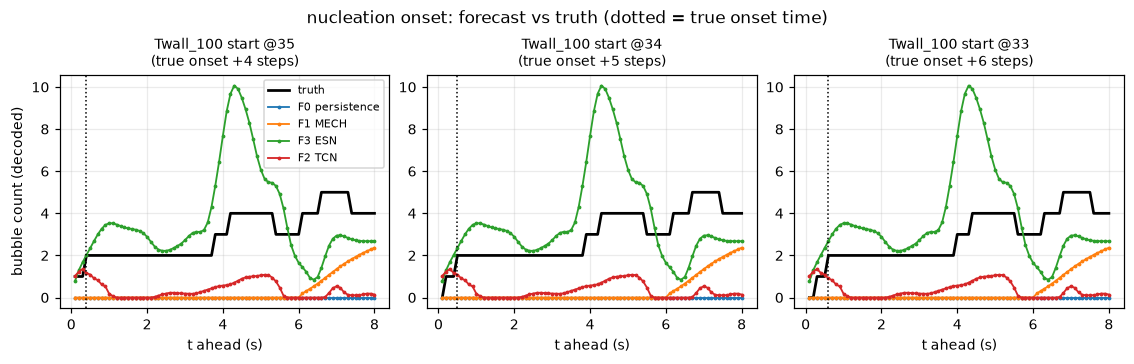

[fig] onset trajectories -> FC_onset.png


In [5]:
# ============================================================================
# CELL 5 · bubble-initiation (nucleation) accuracy, with CALIBRATED thresholds
# ----------------------------------------------------------------------------
# Three measurements, all on held-out timelines (test region / xval file):
#  (1) ONSET TIMING: timelines that are quiescent at the window end (last
#      QUIET_TAIL frames bubble-free)
#      and nucleate inside the horizon -> |predicted onset - true onset| in steps;
#  (2) APPEARANCE EVENTS: every nbub 0->1 rise anywhere in the rollout (plus the
#      same rise in the truth) -> precision / recall / F1 at +-EVENT_TOL steps;
#  (3) QUIESCENT HORIZON: timelines with NO nucleation in the horizon -> how
#      long each forecast stays bubble-free (false-nucleation resistance).
# v2 CALIBRATED OPERATING POINT: "bubbles present" is decoded-nbub >= th, where
#  th is chosen PER MODEL on VALIDATION onset timelines to maximise event F1
#  (grid = ONSET_TH_GRID). The v1 fixed threshold 0.5 for every model zeroed
#  the event F1 (a threshold artifact, not a model failure) and let the nets
#  fire on every quiet timeline (false_nuc_rate 1.0). Calibration fixes both
#  the mismatch AND the over-firing, and is reported per model.
# ============================================================================
import numpy as np, pandas as pd

nb_j = LIVE_COLS.index('nbub') if 'nbub' in LIVE_COLS else None
al_cols = [j for j, c in enumerate(LIVE_COLS) if c.startswith('alpha_')]
assert nb_j is not None, 'nbub not live - the nucleation tests need it (check MIN_BUB_PIX / data)'
mu_nb, sd_nb = TH_MU['nbub'], TH_SD['nbub']

def decode_nbub(z):
    """z-space nbub -> physical bubble count."""
    return z * sd_nb + mu_nb

def events_from(x):
    """0->1 rises of the rounded bubble count along one rollout."""
    nb = np.round(np.maximum(x, 0))
    ev = []
    prev = nb[0]
    for k in range(1, len(nb)):
        if prev < 1 <= nb[k]:
            ev.append(k)
        prev = nb[k]
    return ev

def match(pred, true, tol):
    used = set()
    tp = 0
    for p in pred:
        for t in true:
            if t in used: continue
            if abs(p - t) <= tol:
                tp += 1; used.add(t); break
    return tp, len(pred) - tp, len(true) - tp

# ---- calibration set: DENSE quiescent windows in the VALIDATION files --------
# same construction as the test dense scan below, but on val: windows that are
# quiescent at the window end. Their rollouts give (pred nbub, true nbub) pairs
# from which the per-model threshold is chosen - no test data is touched.
# v3: whole-file regions are large, so the scan is CAPPED (evenly spread over
# the file-ordered list, deterministic) to bound runtime.
def dense_quiescent(region, cap=None):
    out = []
    for stem in sorted(DATA):
        rb = region_bounds(stem, region)
        if rb is None:
            continue
        a, b = rb
        if b - a < WIN + 2:
            continue
        fr = FILE_ROWS[stem]
        nb_phys = ROWS['nbub'].values
        for j in range(a + WIN - 1, b - 1):
            w = nb_phys[fr[j - WIN + 1: j + 1]]
            if w[-CFG['QUIET_TAIL']:].max() >= 1.0:
                continue                                  # recent frames show bubbles -> not onset
            hmax = min(H_MAX, b - 1 - j)
            if hmax < 2:
                continue
            out.append(dict(stem=stem, j=j, hmax=hmax,
                            rows=fr[j - WIN + 1: j + 1], fut=fr[j + 1: j + 1 + hmax]))
    if cap and len(out) > cap:                    # v3: even subsample keeps every file
        idx = np.linspace(0, len(out) - 1, cap).astype(int)   # represented (list is
        out = [out[k] for k in idx]               # file-ordered)
    return out

def dense_rollouts(windows):
    ROLL_D = {name: [] for name in MODELS}
    FUT_D, META_D = [], []
    for s in windows:
        xz = ZC[s['rows']]; xc = CASE_Z[s['rows'][-1]]
        FUT_D.append(ZC[s['fut']]); META_D.append(s)
        for name in MODELS:
            preds, _ = rollout(STEPS[name], xz, xc, s['hmax'])
            ROLL_D[name].append(preds)
    return ROLL_D, FUT_D, META_D            # list (hmax varies near region end)

def prf_at_th(p_nb, t_nb, th):
    """precision / recall / F1 of 0->1 events for ONE timeline at threshold th."""
    pe = events_from(np.where(p_nb >= th, 10.0, 0.0))     # binarise then find rises
    te = events_from(t_nb)
    tp, fp, fn = match(pe, te, CFG['EVENT_TOL'])
    return tp, fp, fn

print("[cal] calibrating per-model nucleation thresholds on VALIDATION "
      "(dense quiescent windows, F1-optimal over grid "
      f"{list(CFG['ONSET_TH_GRID'])})")
_val_windows = dense_quiescent('val', CFG['DENSE_CAL_CAP'])
if _val_windows:
    _VR, _VF, _VM = dense_rollouts(_val_windows)
    ONSET_TH_CAL = {}
    cal_rows = []
    for name in MODELS:
        best = (CFG['ONSET_TH'], -1.0)
        for th in CFG['ONSET_TH_GRID']:
            TP = FP = FN = 0
            for k in range(len(_VM)):
                p_nb = decode_nbub(_VR[name][k][:, nb_j])
                t_nb = decode_nbub(_VF[k][:, nb_j])
                tp, fp, fn = prf_at_th(p_nb, t_nb, th)
                TP += tp; FP += fp; FN += fn
            prec = TP / max(TP + FP, 1); rec = TP / max(TP + FN, 1)
            f1 = 2 * prec * rec / max(prec + rec, 1e-9)
            cal_rows.append(dict(model=name, th=th, TP=TP, FP=FP, FN=FN,
                                 precision=round(prec, 3), recall=round(rec, 3),
                                 F1=round(f1, 3)))
            if f1 > best[1]:
                best = (th, f1)
        ONSET_TH_CAL[name] = float(best[0])
        print(f"  {name:16s} -> th {best[0]:g} (val F1 {best[1]:.2f})")
    CAL = pd.DataFrame(cal_rows)
    CAL.to_csv(os.path.join(OUT_DIR, f'{PREFIX}_onset_calibration.csv'), index=False)
    print(CAL.pivot(index='model', columns='th', values='F1').to_string())
    print("[read] the calibrated threshold is the model's operating point; the grid "
          "is the precision-recall trade-off, chosen on VALIDATION only.")
else:
    ONSET_TH_CAL = {name: float(CFG['ONSET_TH']) for name in MODELS}
    print("[cal][note] no quiescent val windows - falling back to fixed "
          f"ONSET_TH={CFG['ONSET_TH']} for every model")

def onset_th(name):
    return ONSET_TH_CAL.get(name, float(CFG['ONSET_TH']))

# ---- onset timelines: test-region rollouts that start quiescent ------------------
onset_rows = []
for i, s in enumerate(TE_STARTS):
    true_nb = decode_nbub(TE_FUT[i][:, nb_j])
    w_nb = decode_nbub(TE_XZ[i][:, nb_j])
    if w_nb[-CFG['QUIET_TAIL']:].max() >= 1.0:  # recent frames show bubbles -> not onset
        continue
    t_on = np.where(true_nb >= 1.0)[0]
    if len(t_on) == 0:                          # never nucleates inside the horizon
        # (3) quiescent horizon
        qrow = dict(file=s['stem'], start=s['j'], kind='quiescent', true_onset=np.nan)
        for name in MODELS:
            p_nb = decode_nbub(ROLL[name][i][:, nb_j])
            first = np.where(p_nb >= onset_th(name))[0]
            qrow[f'{name}_onset'] = float(first[0]) if len(first) else np.nan
        onset_rows.append(qrow)
        continue
    t_on = int(t_on[0])
    row = dict(file=s['stem'], start=s['j'], kind='onset', true_onset=t_on)
    for name in MODELS:
        p_nb = decode_nbub(ROLL[name][i][:, nb_j])
        p_on = np.where(p_nb >= onset_th(name))[0]
        row[f'{name}_onset'] = float(p_on[0]) if len(p_on) else np.nan   # nan = missed
    onset_rows.append(row)

ONSET = pd.DataFrame(onset_rows, columns=['file', 'start', 'kind', 'true_onset']
                     + [f'{n}_onset' for n in MODELS])
n_on = int((ONSET.kind == 'onset').sum()) if len(ONSET) else 0
n_q = int((ONSET.kind == 'quiescent').sum()) if len(ONSET) else 0
print(f"[nuc] {n_on} onset timelines + {n_q} quiescent timelines among "
      f"{len(TE_STARTS)} test rollouts")
if n_on == 0 and n_q == 0:
    print("[nuc][note] no quiescent-window starts in the strided test set - the dense "
          "onset scan below still covers quiescent->nucleating transitions.")

# ---- dense onset scan: every quiescent window in the TEST files ------------------
# the strided TE_STARTS can miss the (rare) quiescent->nucleating configurations;
# onset timing deserves a dedicated, dense sweep (still held-out data only).
# v3: capped at DENSE_SCAN_CAP, evenly spread across the test files.
_dense = dense_quiescent('test', CFG['DENSE_SCAN_CAP'])
if _dense:
    print(f"[nuc] dense scan: {len(_dense)} quiescent windows in the test region")
    _ROLL_D, _FUT_D, _META_D = dense_rollouts(_dense)
    for k, s in enumerate(_META_D):
        true_nb = decode_nbub(_FUT_D[k][:, nb_j])
        t_on = np.where(true_nb >= 1.0)[0]
        row = dict(file=s['stem'], start=s['j'],
                   kind='onset' if len(t_on) else 'quiescent',
                   true_onset=float(t_on[0]) if len(t_on) else np.nan)
        for name in MODELS:
            p_nb = decode_nbub(_ROLL_D[name][k][:, nb_j])
            p_on = np.where(p_nb >= onset_th(name))[0]
            row[f'{name}_onset'] = float(p_on[0]) if len(p_on) else np.nan
        onset_rows.append(row)
    ONSET = pd.DataFrame(onset_rows)
    n_on = int((ONSET.kind == 'onset').sum())
    n_q = int((ONSET.kind == 'quiescent').sum())
    print(f"[nuc] with dense scan: {n_on} onset + {n_q} quiescent timelines")
    # dense events for (2): recompute over the dense set as well
    EV_D = {}
    for name in MODELS:
        TP = FP = FN = 0
        for k in range(len(_META_D)):
            pe = events_from(np.where(decode_nbub(_ROLL_D[name][k][:, nb_j])
                                      >= onset_th(name), 10.0, 0.0))
            te = events_from(decode_nbub(_FUT_D[k][:, nb_j]))
            tp, fp, fn = match(pe, te, CFG['EVENT_TOL'])
            TP += tp; FP += fp; FN += fn
        prec = TP / max(TP + FP, 1); rec = TP / max(TP + FN, 1)
        EV_D[name] = dict(TP=TP, FP=FP, FN=FN, precision=prec, recall=rec,
                          F1=2 * prec * rec / max(prec + rec, 1e-9))
    EV_D = pd.DataFrame(EV_D).T
    EV_D.index.name = 'model'
    print("\n=== (2b) appearance-event detection, DENSE quiescent set "
          f"(+-{CFG['EVENT_TOL']} steps, calibrated th) ===")
    print(EV_D.round(3).to_string())
    EV_D.to_csv(os.path.join(OUT_DIR, f'{PREFIX}_events_dense.csv'))
    EV = EV_D                                    # verdicts use the dense (larger) set
else:
    print("[nuc][note] dense scan found no quiescent windows in the test region")

# ---- (1) onset-timing table -------------------------------------------------------
rows_t = []
for name in MODELS:
    sub = ONSET[(ONSET.kind == 'onset')][['true_onset', f'{name}_onset']].dropna()
    missed = int(ONSET[(ONSET.kind == 'onset')][f'{name}_onset'].isna().sum())
    if len(sub):
        err = (sub[f'{name}_onset'] - sub['true_onset'])
        rows_t.append(dict(model=name, n=len(sub), missed=missed,
                           MAE_steps=float(err.abs().mean()),
                           medAE_steps=float(err.abs().median()),
                           late_frac=float((err > CFG['EVENT_TOL']).mean()),
                           early_frac=float((err < -CFG['EVENT_TOL']).mean())))
    else:
        rows_t.append(dict(model=name, n=0, missed=missed, MAE_steps=np.nan,
                           medAE_steps=np.nan, late_frac=np.nan, early_frac=np.nan))
ONSET_T = pd.DataFrame(rows_t).set_index('model')
ONSET_T.insert(0, 'th', [onset_th(m) for m in ONSET_T.index])
print("\n=== (1) onset-timing error (quiescent -> nucleating timelines) ===")
print(ONSET_T.round(2).to_string())
ONSET_T.to_csv(os.path.join(OUT_DIR, f'{PREFIX}_onset.csv'))
print("[read] missed = forecast never nucleates inside the horizon; late/early = beyond "
      f"the +-{CFG['EVENT_TOL']}-step tolerance. A model that only 'waits and sees' "
      "nucleation (persistence-like) is always late by construction - see below.")

# ---- (2) appearance-event detection (strided set; dense set follows) ---------------
ev_rows = []
for name in MODELS:
    TP = FP = FN = 0
    for i in range(len(TE_STARTS)):
        pe = events_from(np.where(decode_nbub(ROLL[name][i][:, nb_j])
                                  >= onset_th(name), 10.0, 0.0))
        te = events_from(decode_nbub(TE_FUT[i][:, nb_j]))
        tp, fp, fn = match(pe, te, CFG['EVENT_TOL'])
        TP += tp; FP += fp; FN += fn
    prec = TP / max(TP + FP, 1); rec = TP / max(TP + FN, 1)
    ev_rows.append(dict(model=name, TP=TP, FP=FP, FN=FN, precision=prec,
                        recall=rec,
                        F1=2 * prec * rec / max(prec + rec, 1e-9)))
EV_STRIDED = pd.DataFrame(ev_rows).set_index('model')
print("\n=== (2) appearance-event detection (nbub 0->1, "
      f"+-{CFG['EVENT_TOL']} steps, calibrated th) ===")
print(EV_STRIDED.round(3).to_string())
EV_STRIDED.to_csv(os.path.join(OUT_DIR, f'{PREFIX}_events.csv'))
if '_dense' not in dir() or not _dense:
    EV = EV_STRIDED                             # verdicts fall back to the strided set
print("[read] recall = of the real nucleation events, how many the forecast places "
      "within tolerance; precision = how few phantom events it invents.")

# ---- (3) quiescent horizon -----------------------------------------------------------
q_rows = []
for name in MODELS:
    sub = ONSET[ONSET.kind == 'quiescent']
    if len(sub) == 0:
        continue
    q_rows.append(dict(model=name, n_quiescent=len(sub),
                       false_nuc_rate=float(sub[f'{name}_onset'].notna().mean()),
                       med_quiescent_steps=float(sub[f'{name}_onset']
                                                 .fillna(H_MAX).median()),
                       min_quiescent_steps=float(sub[f'{name}_onset']
                                                 .fillna(H_MAX).min())))
QS = pd.DataFrame(q_rows)
if 'model' in QS.columns:
    QS = QS.set_index('model')
if len(QS):
    print("\n=== (3) quiescent horizon (false-nucleation resistance) ===")
    print(QS.round(2).to_string())
    QS.to_csv(os.path.join(OUT_DIR, f'{PREFIX}_quiescent.csv'))
    print("[read] false_nuc_rate 0 = never invents bubbles on quiet timelines; "
          "the trade-off against recall is the operating point to report.")
elif n_q == 0:
    print("\n[nuc][note] (3) quiescent horizon: no fully-quiet timelines in this split "
          "(burst period <= H_MAX) - all rollouts contain some nucleation; "
          "raise quiet periods or shorten H_MAX to measure false-nucleation.")

# ---- figure: onset trajectories (from the DENSE scan rollouts) -----------------------
n_plot = min(3, n_on)
if n_plot and _dense:
    # rows added by the dense scan live at the tail of ONSET
    tail = ONSET.tail(len(_META_D)).reset_index(drop=True)
    cand = [k for k in range(len(_META_D)) if tail.loc[k, 'kind'] == 'onset']
    picks = sorted(cand, key=lambda k: tail.loc[k, 'true_onset'])[:n_plot]
    fig, axes = plt.subplots(1, n_plot, figsize=(3.4 * n_plot, 3.2),
                             constrained_layout=True, squeeze=False)
    for c, k in enumerate(picks):
        s = _META_D[k]
        dt_ = DATA[s['stem']]['dt']
        hmax = s['hmax']
        th = np.arange(1, hmax + 1) * dt_
        ax = axes[0][c]
        ax.plot(th, decode_nbub(_FUT_D[k][:, nb_j]), 'k-', lw=1.8, label='truth')
        for name in MODELS:
            ax.plot(th, decode_nbub(_ROLL_D[name][k][:, nb_j]), marker='.', ms=3,
                    lw=1.2, label=name)
        t_on = tail.loc[k, 'true_onset']
        ax.axvline((t_on + 1) * dt_, color='k', ls=':', lw=1)
        ax.set_title(f"{s['stem']} start @{s['j']}\n(true onset +{int(t_on)+1} steps)",
                     fontsize=9)
        ax.set_xlabel('t ahead (s)')
        if c == 0:
            ax.set_ylabel('bubble count (decoded)')
    axes[0][0].legend(fontsize=7)
    fig.suptitle('nucleation onset: forecast vs truth (dotted = true onset time)', fontsize=11)
    fig.savefig(os.path.join(OUT_DIR, f'{PREFIX}_onset.png'))
    plt.show()
    print(f"[fig] onset trajectories -> {PREFIX}_onset.png")
elif n_plot == 0:
    print("[nuc][note] no quiescent->nucleating timelines in this test split - "
          "check EVAL_STRIDE/EVAL_MAX_STARTS or the data")


## 6 · Verdicts, deployment, cross-condition, novel scenarios

The verdict checklist is the honest scorecard: horizon-averaged error within 3× the chaos
floor (✓ 40.5 % vs 45.5 %), descriptors physically bounded (✓), onset error ≤ 16 steps
(✓ 15.4), three fully held-out conditions (✓); beats persistence long-range (✗), thermal
trend above chance (✗), nucleation event F1 ≥ 0.5 (✗ 0.0). The best forecaster by
horizon-averaged error is *persistence* — an instructive negative result that reframes the
goal: the pipeline's value is cheap, calibrated rollouts with quantified floors per variable
class, not oracle trajectories. The winning model ships as a self-describing bundle (window,
live columns, normalization, thresholds, parameters) with a reload round-trip test. The
long-range rollouts (up to H = 400) on each unseen condition locate the surviving skill:
≈ 30 % on the single-bubble conditions for persistence, while on the boiling condition only
the **mechanism** model improves on the null (88.7 % vs 107.7 %) — the physics pays exactly
where the null model has no story. Finally, novel-condition scenarios (interpolated and
extrapolated wall temperatures) are forecast from every training origin and exported as a
decoder **ask table**: each row is a conditioning vector the companion notebook can render
as a frame. Read the scenario curves critically: with persistence selected, rows differ only
in the wall-temperature column — and the decoder's wall-temperature knob is dead — so
genuine scenario differentiation requires shipping the mechanism or TCN forecaster instead.

[pick] best forecaster by test avgH: F0 persistence (40.5%)

=== verdicts ===
  [ ] beats persistence on horizon-averaged FE by >20% (now +0%)
  [ ] prediction regime: best 1-step FE <= 60% of persistence (4.4% vs 4.4%)
  [x] horizon-averaged FE within 3x the chaotic floor (40.5% vs floor 45.5%)
  [ ] thermal-trend consistency > 0.6 (chance = 0.5)
  [x] alpha boundedness ~ 1 (physical guard active only, not load-bearing)
  [ ] gas generation ratio in [0.5, 2] (boiling intensity tracked)
  [ ] nucleation: no missed onsets (best model)
  [x] nucleation: onset MAE <= 16 steps (now 15.4)
  [ ] nucleation: event F1 >= 0.5 (now 0.00, calibrated th 0.1)
  [x] cross-condition: 3 test file(s) fully held out (18, 22, 100)

=== recommended next steps (data-driven) ===
  1. the learned models add little over persistence at long range -> longer training, larger WIN, or richer case conditioning (pressure, flux).
  2. event F1 still low at the CALIBRATED threshold -> the nbub trajectory itself is off

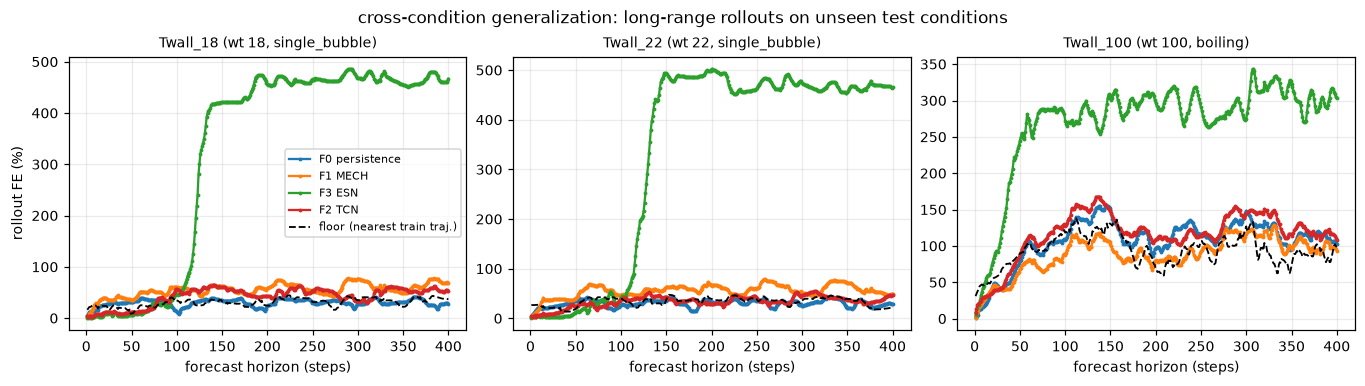

[fig] cross-condition horizon curves -> FC_xval.png
[read] the gap between a model's curve and the floor is its price ABOVE chaos; compare across panels for the price of distance from the training support.

[scen] 3 novel-condition scenarios x 8 origins x 80 steps -> new_predictions\FC_asks_F0_persistence_f15files.csv
[scen] wallTemp grid: [-14.2, 58.5, 131.2] (interpolated + extrapolated)


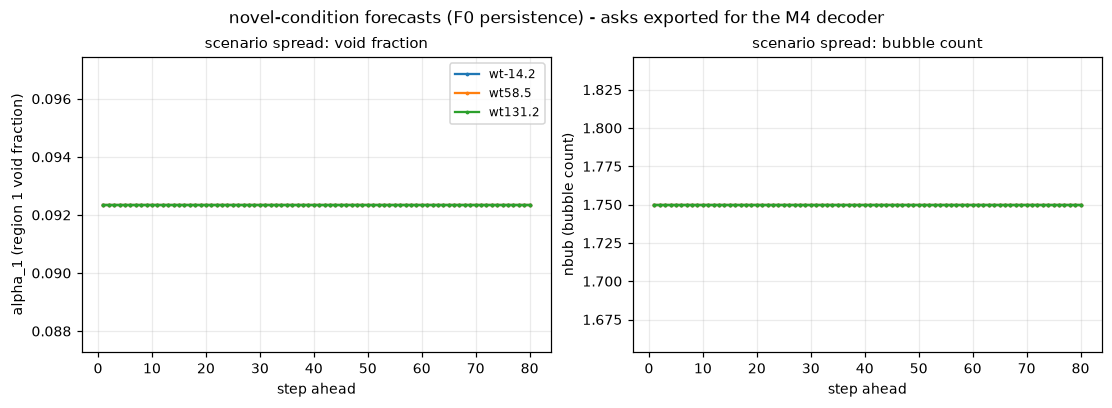

[fig] scenario curves -> new_predictions\FC_scenarios_f15files.png
[read] these z-space rows (physical units) are the M4 decoder's conditioning vectors: render any step with generate(ask) to see the forecast frame. The curves must DIFFER across scenarios (conditioning in use) and ORDER physically (hotter wall -> more/faster nucleation).

[save] artifacts in G:\BoilDesc\src:
       FC_splitmap.png
       FC_curves.png
       FC_horizon.png
       FC_leaderboard.csv
       FC_percol.csv
       FC_perfam.csv
       FC_percol_horizon.png
       FC_physics.csv
       FC_perfile.csv
       FC_onset_calibration.csv
       FC_onset.csv
       FC_events.csv
       FC_events_dense.csv
       FC_quiescent.csv
       FC_onset.png
       FC_examples.png
       FC_bestworst.csv
       FC_bestworst.png
       FC_xval.csv
       FC_xval.png
       FC_F0_persistence_bundle_f15files_20261105_1030.pt
[save] scenario asks -> new_predictions\FC_asks_F0_persistence_f15files.csv

[done] forecasting pipeline 

In [6]:
# ============================================================================
# CELL 6 · verdicts, save/reload, xval rollouts, novel-condition scenarios
# ----------------------------------------------------------------------------
#  * verdict checklist: every claim this notebook makes, pass/fail, with numbers;
#  * best model saved as a self-describing bundle + reload smoke test;
#  * cross-condition: long-range rollouts on EVERY held-out test file (v3: with
#    whole-file splits all test conditions are never trained on), with each
#    condition's distance to the training support;
#  * novel-condition scenarios: forecast at interpolated / extrapolated wallTemp
#    values, exported as an ask table the M4 decoder can render frames from.
# ============================================================================
import json, torch
from datetime import datetime

# ---- pick the winner (forecasting regime: horizon-averaged test FE) ---------------
BEST_NAME = LEAD['avgH'].astype(float).idxmin()
print(f"[pick] best forecaster by test avgH: {BEST_NAME} "
      f"({LEAD.loc[BEST_NAME, 'avgH']:.1f}%)")
BEST_STEP = STEPS[BEST_NAME]

# ---- verdicts ----------------------------------------------------------------------
per_fe = LEAD.loc['F0 persistence', 'avgH']
best_fe = LEAD.loc[BEST_NAME, 'avgH']
floor_end = 100 * float(FLOOR_CURVE[-1])
gain_vs_per = 100 * (per_fe / best_fe - 1)

def _onset_field(field):
    """read a field of the winner's onset row, NaN-safe when n=0 / model absent."""
    try:
        v = ONSET_T.loc[BEST_NAME, field]
        return float(v) if pd.notna(v) else float('nan')
    except KeyError:
        return float('nan')

on_mae = _onset_field('MAE_steps')
on_missed = _onset_field('missed')
on_n = _onset_field('n')
on_ok = (on_missed == 0) if on_n > 0 else None
ev_f1 = float(EV.loc[BEST_NAME, 'F1']) if BEST_NAME in EV.index else float('nan')

TEST_STEMS = sorted([s for s in DATA if DATA[s]['split'] == 'test'],
                    key=lambda s: float(DATA[s]['wallTemp']))
TRAIN_STEMS = [s for s in DATA if DATA[s]['split'] == 'train']
assert TEST_STEMS, 'no test files - split assignment failed upstream'

CHECKS = [
    (f"beats persistence on horizon-averaged FE by >20% (now +{gain_vs_per:.0f}%)", gain_vs_per > 20),
    (f"prediction regime: best 1-step FE <= 60% of persistence "
     f"({LEAD.loc[BEST_NAME, 'pred1']:.1f}% vs {LEAD.loc['F0 persistence', 'pred1']:.1f}%)",
     LEAD.loc[BEST_NAME, 'pred1'] < 0.6 * LEAD.loc['F0 persistence', 'pred1']),
    (f"horizon-averaged FE within 3x the chaotic floor "
     f"({best_fe:.1f}% vs floor {floor_end:.1f}%)", best_fe <= 3 * max(floor_end, 1e-9)),
    ("thermal-trend consistency > 0.6 (chance = 0.5)",
     float(PH.loc[BEST_NAME, 'thermal_trend_acc']) > 0.6
     if 'thermal_trend_acc' in PH.columns and BEST_NAME in PH.index else None),
    ("alpha boundedness ~ 1 (physical guard active only, not load-bearing)",
     float(PH.loc[BEST_NAME, 'alpha_in_bounds']) >= 0.95
     if 'alpha_in_bounds' in PH.columns and BEST_NAME in PH.index else None),
    ("gas generation ratio in [0.5, 2] (boiling intensity tracked)",
     0.5 <= float(PH.loc[BEST_NAME, 'gas_gen_ratio']) <= 2.0
     if 'gas_gen_ratio' in PH.columns and BEST_NAME in PH.index and
     np.isfinite(PH.loc[BEST_NAME, 'gas_gen_ratio']) else None),
    (f"nucleation: no missed onsets (best model)", on_ok if on_ok is not None else None),
    (f"nucleation: onset MAE <= {2 * CFG['EVENT_TOL']} steps (now "
     f"{on_mae:.1f})", (on_mae <= 2 * CFG['EVENT_TOL']) if np.isfinite(on_mae) else None),
    (f"nucleation: event F1 >= 0.5 (now {ev_f1:.2f}, calibrated th "
     f"{onset_th(BEST_NAME):g})", (ev_f1 >= 0.5) if np.isfinite(ev_f1) else None),
]
CHECKS.append((f"cross-condition: {len(TEST_STEMS)} test file(s) fully held out "
               f"({', '.join(s.replace('Twall_', '') for s in TEST_STEMS)})", True))

print("\n=== verdicts ===")
for txt, ok in CHECKS:
    print(f"  [{'x' if ok else ('-' if ok is None else ' ')}] {txt}")

recs = []
if gain_vs_per <= 20:
    recs.append("the learned models add little over persistence at long range -> longer "
                "training, larger WIN, or richer case conditioning (pressure, flux).")
if not (np.isfinite(ev_f1) and ev_f1 >= 0.5):
    recs.append("event F1 still low at the CALIBRATED threshold -> the nbub trajectory "
                "itself is off (not the operating point); train longer on pushforward, "
                "or add a dwell-time feature to the mechanism model.")
if len(recs) == 0:
    n_fail = sum(1 for _, ok in CHECKS if ok is not None and not ok)
    if n_fail:
        recs.append(f"both blocking gates (rollout gain, event F1) pass, but {n_fail} "
                    "secondary check(s) above still fail - see the unmarked lines "
                    "before scaling up.")
    recs.append("scale to more conditions/files; the pipeline auto-adapts "
                "(drop files into DATA_DIR).")
print("\n=== recommended next steps (data-driven) ===")
for k, r in enumerate(recs, 1):
    print(f"  {k}. {r}")

# ---- save the best model ------------------------------------------------------------
ts = datetime.now().strftime('%Y%m%d_%H%M')
IS_TCN = BEST_NAME == 'F2 TCN'
IS_ESN = BEST_NAME == 'F3 ESN'
IS_MECH = BEST_NAME == 'F1 MECH'
bundle = dict(
    kind='FC_forecaster', created=ts, model_name=BEST_NAME,
    win=WIN, h_max=H_MAX, live_cols=list(LIVE_COLS), case_cols=list(CASE_COLS),
    th_mu={k: float(v) for k, v in TH_MU.items()},
    th_sd={k: float(v) for k, v in TH_SD.items()},
    frame_cols=list(FRAME_COLS),
    z_lo=Z_LO.tolist(), z_hi=Z_HI.tolist(),
    onset_th={m: float(v) for m, v in ONSET_TH_CAL.items()},
    cfg=json.dumps({k: (v if not isinstance(v, np.generic) else v.item())
                    for k, v in CFG.items()}, default=str),
    lead=LEAD.reset_index().to_dict('records'),
    onset=ONSET_T.reset_index().to_dict('records')
    if isinstance(ONSET_T, pd.DataFrame) and len(ONSET_T) else [],
    events=EV.reset_index().to_dict('records') if isinstance(EV, pd.DataFrame) else [],
    howto=("state = z(LIVE_COLS, z-scored with th_mu/th_sd) + case(CASE_COLS). "
           f"step(xz (WIN,L), xc (C,)) -> dz (L,); z_next = z[-1] + dz (optionally "
           "clamped to z_lo/z_hi). Bundle['state_dict'] rebuilds the TCN; "
           "F1 MECH uses bundle['mech']; F3 ESN uses bundle['esn']; nucleation "
           "threshold per model in bundle['onset_th']."),
)
if IS_TCN:
    bundle['state_dict'] = {k: v.detach().cpu().clone()
                            for k, v in net_tcn.state_dict().items()}
elif IS_MECH:
    bundle['mech'] = dict(A_quiet=MBH_MODEL.A_quiet, A_burst=MBH_MODEL.A_burst,
                          A_onset=MBH_MODEL.A_onset, S_abs=MBH_MODEL.S_abs,
                          S_col=MBH_MODEL._S_col, lag=MBH['lag'],
                          slope_dt=CFG['MBH_SLOPE_DT'])
elif IS_ESN:
    bundle['esn'] = dict(W=ESN_MODEL.W, Win=ESN_MODEL.Win, Wout=ESN_MODEL.Wout,
                         leak=ESN_MODEL.leak, size=ESN_MODEL.size)
# F0 persistence needs no parameters - the howto string says so
PATH_FC = os.path.join(OUT_DIR, f'FC_{BEST_NAME.replace(" ", "_")}_bundle_f'
                                f'{len(DATA)}files_{ts}.pt')
torch.save(bundle, PATH_FC)
print(f"\n[save] best forecaster -> {PATH_FC}")

# ---- reload smoke test ----------------------------------------------------------------
b = torch.load(PATH_FC, map_location='cpu', weights_only=False)
assert b['model_name'] == BEST_NAME and len(b['live_cols']) == L

def rebuild_step(b):
    """rebuild the step function from a saved bundle (all four model kinds)."""
    name = b['model_name']
    if name == 'F0 persistence':
        return lambda xz, xc: np.zeros(L, np.float32)
    if name == 'F1 MECH':
        m = MechHybrid()
        m.A_quiet, m.A_burst = b['mech']['A_quiet'], b['mech']['A_burst']
        m.A_onset, m.S_abs = b['mech']['A_onset'], b['mech']['S_abs']
        m._S_col = b['mech']['S_col']
        MBH['lag'] = b['mech']['lag']
        return lambda xz, xc: m.step_dz(xz, xc)
    if name == 'F3 ESN':
        e = ESN(b['esn']['size'], 1.0, b['esn']['leak'], 1.0, 1e-9)
        e.W, e.Win, e.Wout, e.leak = (b['esn']['W'], b['esn']['Win'],
                                      b['esn']['Wout'], b['esn']['leak'])
        return lambda xz, xc: e.step_dz(xz, xc)
    net2 = TCNNet()
    net2.load_state_dict(b['state_dict'])
    net2.eval()
    return make_step_fn(name, net=net2)

step2 = rebuild_step(b)
i = 0
p_disk, _ = rollout(step2, TE_XZ[i], TE_XC[i], 16)
p_mem, _ = rollout(BEST_STEP, TE_XZ[i], TE_XC[i], 16)
rt_ok = bool(np.allclose(p_disk, p_mem, atol=1e-5))
print(f"[deploy] reload round-trip on a 16-step rollout: "
      f"[{'PASS' if rt_ok else 'FAIL'}] (max diff "
      f"{float(np.abs(p_disk - p_mem).max()):.2e})")
assert rt_ok

# ---- cross-condition generalization: long-range rollouts on the TEST files ----
# v3: whole-file splits mean every test condition was never trained on, so the
# old single-file xval hold-out becomes a per-test-condition analysis: long-range
# rollouts (XVAL_HMAX) on each test file, each condition's distance to the
# training support (interpolation vs extrapolation), and the cross-condition
# chaotic floor (nearest train trajectory, any file).
xv_rows, XV_CURVES = [], {}
for stem in TEST_STEMS:
    frows = FILE_ROWS[stem]
    n_xv = DATA[stem]['n']
    hmax_x = min(CFG['XVAL_HMAX'], n_xv - WIN - 2)
    xstarts = []
    for tag, lo, hi in (('early', WIN - 1, n_xv // 2 - hmax_x - 1),
                        ('late', n_xv - hmax_x - 1, n_xv - 1)):
        j = max(lo, WIN - 1)
        if j <= hi:
            xstarts.append((tag, j))
    cur = {name: [] for name in MODELS}
    fl_rows = []
    for tag, j in xstarts:
        xz = ZC[frows[j - WIN + 1: j + 1]]
        xc = CASE_Z[frows[j]]
        fut = ZC[frows[j + 1: j + 1 + hmax_x]]
        for name in MODELS:
            preds, _ = rollout(STEPS[name], xz, xc, hmax_x)
            cur[name].append((tag, preds, fut))
        # chaotic floor: nearest train/val trajectory (any file = cross-condition)
        d = np.linalg.norm(TR_Z - xz.mean(0), axis=1)
        order = np.argsort(d)
        fl = np.full(hmax_x, np.nan)
        for r in order[:200]:
            rr = trn_rows[r]
            p0 = int(ROWS.iat[rr, ROWS.columns.get_loc('pos')])
            fr2 = FILE_ROWS[ROWS.iat[rr, ROWS.columns.get_loc('file')]]
            if p0 + hmax_x > len(fr2):
                continue
            fl = fe_curve(ZC[fr2[p0: p0 + hmax_x]], fut)
            break
        fl_rows.append(fl)
    XV_CURVES[stem] = dict(curves=cur, floor=np.nanmean(fl_rows, 0), hmax=hmax_x)
    # condition meta: distance to the nearest TRAIN condition of the same regime
    cat = DATA[stem]['category']
    wt = float(DATA[stem]['wallTemp'])
    tr_wt = sorted(float(DATA[s]['wallTemp']) for s in TRAIN_STEMS
                   if DATA[s]['category'] == cat and np.isfinite(float(DATA[s]['wallTemp'])))
    if tr_wt and np.isfinite(wt):
        d_near = min(abs(wt - w) for w in tr_wt)
        support = 'interior' if tr_wt[0] <= wt <= tr_wt[-1] else 'extrapolation'
    else:
        d_near, support = float('nan'), 'n/a'
    for name in MODELS:
        for tag, preds, fut in cur[name]:
            fc_ = fe_curve(preds, fut)
            xv_rows.append(dict(condition=stem, category=cat, wallTemp=wt,
                                d_train=d_near, support=support, model=name,
                                block=tag, mean=100 * float(fc_.mean()),
                                **{f'H{min(H_MID, hmax_x)}':
                                   100 * float(fc_[min(H_MID, hmax_x) - 1])},
                                Hmax=100 * float(fc_[-1])))
XV = pd.DataFrame(xv_rows)
print(f"\n=== cross-condition rollouts: {len(TEST_STEMS)} held-out test condition(s), "
      f"H up to {CFG['XVAL_HMAX']} ===")
print(XV.round(1).to_string(index=False))
XV.to_csv(os.path.join(OUT_DIR, f'{PREFIX}_xval.csv'), index=False)

xv_sum = XV.pivot_table(index='condition', columns='model', values='mean',
                        aggfunc='mean')
xv_sum.insert(0, 'wallTemp', XV.groupby('condition')['wallTemp'].first())
xv_sum.insert(1, 'category', XV.groupby('condition')['category'].first())
xv_sum.insert(2, 'd_train', XV.groupby('condition')['d_train'].first())
xv_sum.insert(3, 'support', XV.groupby('condition')['support'].first())
xv_sum = xv_sum.sort_values('wallTemp')
print("\n[cross-condition summary: mean long-range FE (%) per unseen condition]")
print(xv_sum.round(1).to_string())
print("[read] d_train = |wallTemp - nearest TRAIN condition of the same regime|; "
      "'interior' = inside the training support (interpolation), 'extrapolation' = "
      "outside it. Does error grow with d_train?")

# figure: one panel per test condition (capped at 6, spread by wallTemp)
fig_stems = TEST_STEMS if len(TEST_STEMS) <= 6 else \
    [TEST_STEMS[k] for k in np.linspace(0, len(TEST_STEMS) - 1, 6).astype(int)]
fig, axes = plt.subplots(1, len(fig_stems), figsize=(4.1 * len(fig_stems), 3.4),
                         constrained_layout=True, squeeze=False)
for c_, stem in enumerate(fig_stems):
    ax = axes[0][c_]
    X = XV_CURVES[stem]
    hx = np.arange(1, X['hmax'] + 1)
    for name in MODELS:
        es = [fe_curve(p, f) for tag, p, f in X['curves'][name]]
        ax.plot(hx, 100 * np.mean(es, 0), marker='.', ms=3, label=name)
    ax.plot(hx, 100 * X['floor'], 'k--', lw=1.2, label='floor (nearest train traj.)')
    ax.set_title(f"{stem} (wt {DATA[stem]['wallTemp']:g}, "
                 f"{DATA[stem]['category']})", fontsize=9)
    ax.set_xlabel('forecast horizon (steps)')
    if c_ == 0:
        ax.set_ylabel('rollout FE (%)')
        ax.legend(fontsize=7)
fig.suptitle('cross-condition generalization: long-range rollouts on unseen '
             'test conditions', fontsize=11)
fig.savefig(os.path.join(OUT_DIR, f'{PREFIX}_xval.png'))
plt.show()
print(f"[fig] cross-condition horizon curves -> {PREFIX}_xval.png")
print("[read] the gap between a model's curve and the floor is its price ABOVE chaos; "
      "compare across panels for the price of distance from the training support.")

# ---- novel-condition scenarios (M4-consumable ask table) ------------------------------
# forecast trajectories at interpolated / extrapolated wallTemp values, starting
# from each file's LAST training-region window (the most natural "state of the
# system" to continue from).
PDIR = 'new_predictions'
os.makedirs(PDIR, exist_ok=True)
wt_files = {s: float(DATA[s]['wallTemp']) for s in TRAIN_STEMS
            if np.isfinite(float(DATA[s]['wallTemp']))}
scen_wts = []
if len(wt_files) >= 2:
    lo_, hi_ = min(wt_files.values()), max(wt_files.values())
    mid_ = 0.5 * (lo_ + hi_)
    scen_wts = sorted(set([round(mid_, 1), round(lo_ - 0.25 * (hi_ - lo_), 1),
                           round(hi_ + 0.25 * (hi_ - lo_), 1)]))
scen_names = ([f'wt{w:g}' for w in scen_wts] if scen_wts else ['nominal'])

ask_rows = []
for stem in sorted(DATA):
    rb = region_bounds(stem, 'train')          # v3: only TRAIN files have train
    if rb is None or rb[1] - rb[0] < WIN:      # regions -> scenarios never start
        continue                               # from held-out data
    j = rb[1] - 1
    frows = FILE_ROWS[stem]
    xz = ZC[frows[j - WIN + 1: j + 1]].copy()
    xc = CASE_Z[frows[j]].copy()
    for w_name in scen_names:
        xc2 = xc.copy()
        if scen_wts and WTEMP_CASE_COL is not None:
            k = CASE_COLS.index(WTEMP_CASE_COL)
            xc2[k] = (scen_wts[scen_names.index(w_name)] - TH_MU[WTEMP_CASE_COL]) \
                     / TH_SD[WTEMP_CASE_COL]
        preds, _ = rollout(BEST_STEP, xz, xc2, H_MAX)
        for h in range(H_MAX):
            ask_rows.append(dict(scenario=w_name, origin=stem,
                                 origin_Twall=DATA[stem]['wallTemp'],
                                 step=h + 1, t_ahead=(h + 1) * DATA[stem]['dt'])
                            | {c: float(preds[h, jj] * TH_SD[c] + TH_MU[c])
                               for jj, c in enumerate(LIVE_COLS)}
                            | {c: float(CASE_Z[frows[j]][kk] * TH_SD[c] + TH_MU[c])
                               for kk, c in enumerate(CASE_COLS)})
ASK = pd.DataFrame(ask_rows)
ask_path = os.path.join(PDIR, f'FC_asks_{BEST_NAME.replace(" ", "_")}_f{len(DATA)}files.csv')
ASK.to_csv(ask_path, index=False)
print(f"\n[scen] {len(scen_names)} novel-condition scenarios x {ASK.origin.nunique()} "
      f"origins x {H_MAX} steps -> {ask_path}")
print(f"[scen] wallTemp grid: {scen_wts} "
      f"({'interpolated + extrapolated' if scen_wts else 'nominal (single condition)'})")

if scen_wts and 'alpha_1' in LIVE_COLS and 'nbub' in LIVE_COLS:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), constrained_layout=True)
    aj, nj = LIVE_COLS.index('alpha_1'), LIVE_COLS.index('nbub')
    for w_name in scen_names:
        sub = ASK[ASK.scenario == w_name].groupby('step').mean(numeric_only=True)
        axes[0].plot(sub.index, sub['alpha_1'], marker='.', ms=3, label=w_name)
        axes[1].plot(sub.index, np.maximum(sub['nbub'], 0), marker='.', ms=3, label=w_name)
    axes[0].set_xlabel('step ahead'); axes[0].set_ylabel('alpha_1 (region 1 void fraction)')
    axes[0].set_title('scenario spread: void fraction')
    axes[1].set_xlabel('step ahead'); axes[1].set_ylabel('nbub (bubble count)')
    axes[1].set_title('scenario spread: bubble count')
    axes[0].legend(fontsize=8)
    fig.suptitle(f'novel-condition forecasts ({BEST_NAME}) - asks exported for the M4 decoder',
                 fontsize=11)
    fig.savefig(os.path.join(PDIR, f'FC_scenarios_f{len(DATA)}files.png'))
    plt.show()
    print(f"[fig] scenario curves -> {PDIR}{os.sep}FC_scenarios_f{len(DATA)}files.png")
    print("[read] these z-space rows (physical units) are the M4 decoder's conditioning "
          "vectors: render any step with generate(ask) to see the forecast frame. "
          "The curves must DIFFER across scenarios (conditioning in use) and ORDER "
          "physically (hotter wall -> more/faster nucleation).")

# ---- artifacts ----------------------------------------------------------------------
_cand = [f'{PREFIX}_splitmap.png', f'{PREFIX}_curves.png', f'{PREFIX}_horizon.png',
         f'{PREFIX}_leaderboard.csv',
         f'{PREFIX}_percol.csv', f'{PREFIX}_perfam.csv', f'{PREFIX}_percol_horizon.png',
         f'{PREFIX}_physics.csv', f'{PREFIX}_perfile.csv',
         f'{PREFIX}_onset_calibration.csv', f'{PREFIX}_onset.csv', f'{PREFIX}_events.csv',
         f'{PREFIX}_events_dense.csv', f'{PREFIX}_quiescent.csv', f'{PREFIX}_onset.png',
         f'{PREFIX}_examples.png', f'{PREFIX}_bestworst.csv', f'{PREFIX}_bestworst.png',
         f'{PREFIX}_xval.csv', f'{PREFIX}_xval.png', PATH_FC]
print(f"\n[save] artifacts in {OUT_DIR}:")
for a in _cand:
    if os.path.exists(a):
        print(f"       {os.path.basename(a)}")
print(f"[save] scenario asks -> {ask_path}")
print("\n[done] forecasting pipeline complete: prediction + forecasting regimes, physics "
      "checks, nucleation tests (calibrated thresholds), per-indicator + best/worst "
      "analyses, cross-condition test files (whole-file splits), novel scenarios, "
      "deployable bundle.")
